In [6]:
# Put the repository root on sys.path, wherever the kernel was started from.
import os, sys

def _find_repo_root():
    _pkgs = ("genotyping", "pipelines", "screening", "sequencing")
    for _cand in [os.getcwd(), *sys.path]:
        if not _cand:
            continue
        _d = os.path.abspath(_cand)
        while True:
            if all(os.path.isdir(os.path.join(_d, _p)) for _p in _pkgs):
                return _d
            _parent = os.path.dirname(_d)
            if _parent == _d:
                break
            _d = _parent
    return None

_repo_root = _find_repo_root()
if _repo_root and _repo_root not in sys.path:
    sys.path.insert(0, _repo_root)

import A9_config as config

import sys
import os
import multiprocessing as mp
import importlib

from pipelines import common_tasks

# Reload the modules
importlib.reload(config)
importlib.reload(common_tasks)

from screening import screen_utils

In [7]:
lib=config.get_library()
lib 

,Unnamed: 0,finalname,lib_section,specific_primerpart,barcode,spacer,target rv,oligofinal,length,target_site_rc_PlusTAM,target_site_PlusTAM,target_site,spacer_CG_regions,target_site_CG_regions
0,NaN,LIB-128,LIB-128,NaN,NaN,GAAGAGGACCTGGGAGATGA,TCATCTCCCAGGTCCTCTTCNNNNN,CGCGACTTTAGTCGTGTGAGGTTCAAGAAGAGGACCTGGGAGATGA...,206,TCATCTCCCAGGTCCTCTTCNNNNN,NNNNNGAAGAGGACCTGGGAGATGA,GAAGAGGACCTGGGAGATGA,GGGGCCGGGGG,GGGGCCGGGGG
1,NaN,LIB-130,LIB-130,NaN,NaN,TATTATATATGAGTTCACTG,CAGTGAACTCATATATAATANNNNN,CGCGACTTTAGTCGTGTGAGGTTCAATATTATATATGAGTTCACTG...,206,CAGTGAACTCATATATAATANNNNN,NNNNNTATTATATATGAGTTCACTG,TATTATATATGAGTTCACTG,GGCCG,GGCCG
2,NaN,LIB-132,LIB-132,NaN,NaN,ATACTGTAAAGAAGCAGAAA,TTTCTGCTTCTTTACAGTATNNNNN,CGCGACTTTAGTCGTGTGAGGTTCAAATACTGTAAAGAAGCAGAAA...,206,TTTCTGCTTCTTTACAGTATNNNNN,NNNNNATACTGTAAAGAAGCAGAAA,ATACTGTAAAGAAGCAGAAA,CGGGCG,CGGGCG


In [8]:
samples= config.get_samples()
samples 

,sample_name,sequencing_name,bioreplicate,replicate,file_name_R1,file_name_R2,editor,is_ctrl,lib_section
0,A9-06_Sample-1_TnpB-WT_ABE_LIB-128_d10_rep1,A9-06_Sample-1,TnpB-WT_ABE_LIB-128_d10,1,377671_385-A9-06_Sample-1_S372_R1_001.fastq.gz,377671_385-A9-06_Sample-1_S372_R2_001.fastq.gz,TnpB-WT_ABE,no,LIB-128
1,A9-06_Sample-2_TnpB-Var1-140_ABE_LIB-128_d10_rep1,A9-06_Sample-2,TnpB-Var1-140_ABE_LIB-128_d10,1,377671_386-A9-06_Sample-2_S342_R1_001.fastq.gz,377671_386-A9-06_Sample-2_S342_R2_001.fastq.gz,TnpB-Var1-140_ABE,no,LIB-128
2,A9-06_Sample-3_TnpB-Var2-163_ABE_LIB-128_d10_rep1,A9-06_Sample-3,TnpB-Var2-163_ABE_LIB-128_d10,1,377671_387-A9-06_Sample-3_S50_R1_001.fastq.gz,377671_387-A9-06_Sample-3_S50_R2_001.fastq.gz,TnpB-Var2-163_ABE,no,LIB-128
3,A9-06_Sample-4_TnpB-Var3-164_ABE_LIB-128_d10_rep1,A9-06_Sample-4,TnpB-Var3-164_ABE_LIB-128_d10,1,377671_388-A9-06_Sample-4_S233_R1_001.fastq.gz,377671_388-A9-06_Sample-4_S233_R2_001.fastq.gz,TnpB-Var3-164_ABE,no,LIB-128
4,A9-06_Sample-5_NOEDITOR_LIB-128_d10_rep1,A9-06_Sample-5,NOEDITOR_LIB-128_d10,1,377671_389-A9-06_Sample-5_S280_R1_001.fastq.gz,377671_389-A9-06_Sample-5_S280_R2_001.fastq.gz,NOEDITOR,yes,LIB-128
5,A9-06_Sample-6_TnpB-WT_ABE_LIB-130_d10_rep1,A9-06_Sample-6,TnpB-WT_ABE_LIB-130_d10,1,377671_390-A9-06_Sample-6_S86_R1_001.fastq.gz,377671_390-A9-06_Sample-6_S86_R2_001.fastq.gz,TnpB-WT_ABE,no,LIB-130
6,A9-06_Sample-7_TnpB-Var1-140_ABE_LIB-130_d10_rep1,A9-06_Sample-7,TnpB-Var1-140_ABE_LIB-130_d10,1,377671_391-A9-06_Sample-7_S297_R1_001.fastq.gz,377671_391-A9-06_Sample-7_S297_R2_001.fastq.gz,TnpB-Var1-140_ABE,no,LIB-130
7,A9-06_Sample-8_TnpB-Var2-163_ABE_LIB-130_d10_rep1,A9-06_Sample-8,TnpB-Var2-163_ABE_LIB-130_d10,1,377671_392-A9-06_Sample-8_S117_R1_001.fastq.gz,377671_392-A9-06_Sample-8_S117_R2_001.fastq.gz,TnpB-Var2-163_ABE,no,LIB-130
8,A9-06_Sample-9_TnpB-Var3-164_ABE_LIB-130_d10_rep1,A9-06_Sample-9,TnpB-Var3-164_ABE_LIB-130_d10,1,377671_393-A9-06_Sample-9_S124_R1_001.fastq.gz,377671_393-A9-06_Sample-9_S124_R2_001.fastq.gz,TnpB-Var3-164_ABE,no,LIB-130
9,A9-06_Sample-10_NOEDITOR_LIB-130_d10_rep1,A9-06_Sample-10,NOEDITOR_LIB-130_d10,1,377671_394-A9-06_Sample-10_S301_R1_001.fastq.gz,377671_394-A9-06_Sample-10_S301_R2_001.fastq.gz,NOEDITOR,yes,LIB-130


# analysis of the results

In [9]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

import A9_config as config
import pandas as pd
import numpy as np
import os
import sys

import os, sys
_repo_root = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if _repo_root not in sys.path:
    sys.path.insert(0, _repo_root)

from screening import screen_utils

# import A13_config as config

# import sys
# import os
# import multiprocessing as mp
import importlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

# import os, sys
_repo_root = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if _repo_root not in sys.path:
    sys.path.insert(0, _repo_root)

# # Reload the modules
importlib.reload(config)
importlib.reload(screen_utils)
# importlib.reload(common_tasks)

<module 'screening.screen_utils' from '/home/tao/code/tnpb-analysis/screening/screen_utils.py'>

In [10]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

def check_A_to_A_or_C(df):
    df['valid_diff_nt'] = df.apply(lambda row: sum(tsl == ts or (tsl == 'A' and ts in ['C', 'G']) for tsl, ts in zip(row['target_site_lib'], row['most_common_diff_target_site'])) if pd.notna(row['most_common_diff_target_site']) else 20, axis=1)
    return df

In [11]:
import pandas as pd
from pathlib import Path

# Assuming config.result_dir is a Path object
csv_files = list(config.result_dir.glob("*.csv"))

# Read and concatenate all CSV files
read_stats = pd.DataFrame() if not csv_files else pd.concat([pd.read_csv(file, header=None, index_col=0).squeeze("columns") for file in csv_files], axis=1).T.reset_index(drop=True)

print(f"Total files read: {len(csv_files)}")
read_stats

# read_stats=pd.read_excel(config.result_dir / 'read_stats.xlsx')
# read_stats

Total files read: 0


""


In [12]:

def normalize_abe_editing_rate(config):
    d = pd.read_csv(config.edit_rate('all-abe-samples-not-normalized'), index_col=0)
    d,d_final = screen_utils.normalize_editing_rate(d,
        col_normalize_over=['barcode','TAM','edit_position'],
        col_rate='edit_rate',
        col_control='is_ctrl',
        ignore_control=['barcode', 'TAM'],
        th_ctrl_missing=0.05
    )
    d.drop(columns=['is_ctrl'])
    d.to_csv(config.edit_rate('all-abe-samples-normalized'))
    d_final.to_csv(config.edit_rate('all-abe-samples-normalized-PlusCtrl'))

def aggregate_abe_replicates(config):
    print("aggregating ABE replicates")
    d = pd.read_csv(config.edit_rate('all-abe-samples-normalized'), index_col=0)
    d=d.loc[~d["edit_rate"].isna(),:]
    # Group by the specified columns and filter groups with exactly all replicates
    d = d.groupby(['editor', 'barcode', 'TAM', 'edit_position']).filter(lambda x: len(x) == 3)
    d = screen_utils.aggregate_replicates(d,
        cols_group=['editor','barcode','TAM','edit_position'], # here editor and barcoe(library) combination is a biological replicate, PAM/TAM is not consider here ?
        col_rate='edit_rate'                             # PAM/TAM is not consider here ?
    ).drop(columns=['sample_name', 'replicate'])
    d.to_csv(config.edit_rate('all-abe-editors'))

    d_plusctrl = pd.read_csv(config.edit_rate('all-abe-samples-normalized-PlusCtrl'), index_col=0)
    d_plusctrl=d_plusctrl.loc[~d_plusctrl["edit_rate"].isna(),:]
    # Group by the specified columns and filter groups with exactly all replicates
    d_plusctrl = d_plusctrl.groupby(['editor', 'barcode', 'TAM', 'edit_position']).filter(lambda x: len(x) == 3)
    d_plusctrl = screen_utils.aggregate_replicates(d_plusctrl,
        cols_group=['editor','barcode','TAM','edit_position'], # here editor and barcoe(library) combination is a biological replicate, PAM/TAM is not consider here ?
        col_rate='edit_rate'                             # PAM/TAM is not consider here ?
    ).drop(columns=['sample_name', 'replicate'])

    d_plusctrl.to_csv(config.edit_rate('all-abe-editors-PlusCtrl'))

In [13]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

## check reads level quality

In [14]:
def get_abe_samples(config,sample_name_column='sample_name',editor_column='editor'):
    samples = config.get_samples()
    return samples.loc[samples[editor_column].str.contains('ABE'),:]

def collect_abe_read_edit_rates(config,sample_name_column='sample_name',editor_column='editor',control_column='control_yes_no'):
    """ Collect edit rates for all samples"""
    print('Collecting ABE edit rates for all samples')
    #samples = get_abe_samples(config,sample_name_column,editor_column)
    samples=config.get_samples()
    all_sample_rates = pd.concat(
        [
            pd.read_csv(config.edit_rate(f'{sample[sample_name_column]}-reads-editedrates-unfiltered'), index_col=0).assign(
                editor=sample[editor_column],
                sample_name=sample[sample_name_column],
                is_ctrl=sample[control_column],
                replicate=sample["replicate"],
            )
            for _,sample in samples.iterrows()
        ]
    ).reset_index(drop=True)
    all_sample_rates.loc[:, 'is_ctrl'] = all_sample_rates.is_ctrl == 'yes'
    return all_sample_rates
    #all_sample_rates.to_csv(config.edit_rate('all-abe-samples-reads-editedrates-unfiltered-not-normalized'))
    

In [15]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

all_abe_samples_reads_editedrates_unfiltered_not_normalized=collect_abe_read_edit_rates(config,sample_name_column='sample_name',
                                                                                        editor_column='editor',control_column="is_ctrl")
print(all_abe_samples_reads_editedrates_unfiltered_not_normalized.shape)

all_abe_samples_reads_editedrates_unfiltered_not_normalized.head(n=3)

(42339, 11)


,spacer,TAM,frac_reads_edited,num_reads,target_site,target_site_lib,edit_positions,editor,sample_name,is_ctrl,replicate
0,GAAGAGGACCTGGGAGATGA,AAAAA,0.013231,5593,AAAAGGGAGGGGGGGGGGGG,GAAGAGGACCTGGGAGATGA,"[2, 3, 5, 8, 15, 17, 20]",TnpB-WT_ABE,A9-06_Sample-1_TnpB-WT_ABE_LIB-128_d10_rep1,False,1
1,GAAGAGGACCTGGGAGATGA,AAAAC,0.006715,10574,AAAGAGGACCTGGGAGATGA,GAAGAGGACCTGGGAGATGA,"[2, 3, 5, 8, 15, 17, 20]",TnpB-WT_ABE,A9-06_Sample-1_TnpB-WT_ABE_LIB-128_d10_rep1,False,1
2,GAAGAGGACCTGGGAGATGA,AAAAG,0.164702,5853,AAAGAGACCTGGGAGATGAG,GAAGAGGACCTGGGAGATGA,"[2, 3, 5, 8, 15, 17, 20]",TnpB-WT_ABE,A9-06_Sample-1_TnpB-WT_ABE_LIB-128_d10_rep1,False,1


In [16]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

all_abe_samples_reads_editedrates_unfiltered_not_normalized=all_abe_samples_reads_editedrates_unfiltered_not_normalized[all_abe_samples_reads_editedrates_unfiltered_not_normalized["TAM"].str.match("^[ATCG]+$")]
print(all_abe_samples_reads_editedrates_unfiltered_not_normalized.shape)

(30720, 11)


In [17]:
lib=config.get_library()
lib

,Unnamed: 0,finalname,lib_section,specific_primerpart,barcode,spacer,target rv,oligofinal,length,target_site_rc_PlusTAM,target_site_PlusTAM,target_site,spacer_CG_regions,target_site_CG_regions
0,NaN,LIB-128,LIB-128,NaN,NaN,GAAGAGGACCTGGGAGATGA,TCATCTCCCAGGTCCTCTTCNNNNN,CGCGACTTTAGTCGTGTGAGGTTCAAGAAGAGGACCTGGGAGATGA...,206,TCATCTCCCAGGTCCTCTTCNNNNN,NNNNNGAAGAGGACCTGGGAGATGA,GAAGAGGACCTGGGAGATGA,GGGGCCGGGGG,GGGGCCGGGGG
1,NaN,LIB-130,LIB-130,NaN,NaN,TATTATATATGAGTTCACTG,CAGTGAACTCATATATAATANNNNN,CGCGACTTTAGTCGTGTGAGGTTCAATATTATATATGAGTTCACTG...,206,CAGTGAACTCATATATAATANNNNN,NNNNNTATTATATATGAGTTCACTG,TATTATATATGAGTTCACTG,GGCCG,GGCCG
2,NaN,LIB-132,LIB-132,NaN,NaN,ATACTGTAAAGAAGCAGAAA,TTTCTGCTTCTTTACAGTATNNNNN,CGCGACTTTAGTCGTGTGAGGTTCAAATACTGTAAAGAAGCAGAAA...,206,TTTCTGCTTCTTTACAGTATNNNNN,NNNNNATACTGTAAAGAAGCAGAAA,ATACTGTAAAGAAGCAGAAA,CGGGCG,CGGGCG


In [18]:

all_abe_samples_reads_editedrates_unfiltered_not_normalized["sample_name"] = all_abe_samples_reads_editedrates_unfiltered_not_normalized["sample_name"].str.split("Sample-").str[-1]
all_abe_samples_reads_editedrates_unfiltered_not_normalized["sample_name"] = all_abe_samples_reads_editedrates_unfiltered_not_normalized["sample_name"].apply(lambda x: "_".join(x.split("_")[1:]))


In [19]:


all_abe_samples_reads_editedrates_unfiltered_not_normalized["bioreplicate"]=all_abe_samples_reads_editedrates_unfiltered_not_normalized["sample_name"].apply(lambda x:x.split("_rep")[0])

all_abe_samples_reads_editedrates_unfiltered_not_normalized.head(n=3)



,spacer,TAM,frac_reads_edited,num_reads,target_site,target_site_lib,edit_positions,editor,sample_name,is_ctrl,replicate,bioreplicate
0,GAAGAGGACCTGGGAGATGA,AAAAA,0.013231,5593,AAAAGGGAGGGGGGGGGGGG,GAAGAGGACCTGGGAGATGA,"[2, 3, 5, 8, 15, 17, 20]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-128_d10_rep1,False,1,TnpB-WT_ABE_LIB-128_d10
1,GAAGAGGACCTGGGAGATGA,AAAAC,0.006715,10574,AAAGAGGACCTGGGAGATGA,GAAGAGGACCTGGGAGATGA,"[2, 3, 5, 8, 15, 17, 20]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-128_d10_rep1,False,1,TnpB-WT_ABE_LIB-128_d10
2,GAAGAGGACCTGGGAGATGA,AAAAG,0.164702,5853,AAAGAGACCTGGGAGATGAG,GAAGAGGACCTGGGAGATGA,"[2, 3, 5, 8, 15, 17, 20]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-128_d10_rep1,False,1,TnpB-WT_ABE_LIB-128_d10


In [20]:
all_abe_samples_reads_editedrates_unfiltered_not_normalized["lib_section"]=all_abe_samples_reads_editedrates_unfiltered_not_normalized["sample_name"].apply(lambda x:x.split("_")[2] if len(x.split("_"))==5 else x.split("_")[1])



In [21]:

all_abe_samples_reads_editedrates_unfiltered_not_normalized=all_abe_samples_reads_editedrates_unfiltered_not_normalized.merge(lib[['lib_section','spacer']], on='lib_section', how='left',suffixes=('', '_LIB'))
print(all_abe_samples_reads_editedrates_unfiltered_not_normalized.shape)
all_abe_samples_reads_editedrates_unfiltered_not_normalized.head(n=3)

(30720, 14)


,spacer,TAM,frac_reads_edited,num_reads,target_site,target_site_lib,edit_positions,editor,sample_name,is_ctrl,replicate,bioreplicate,lib_section,spacer_LIB
0,GAAGAGGACCTGGGAGATGA,AAAAA,0.013231,5593,AAAAGGGAGGGGGGGGGGGG,GAAGAGGACCTGGGAGATGA,"[2, 3, 5, 8, 15, 17, 20]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-128_d10_rep1,False,1,TnpB-WT_ABE_LIB-128_d10,LIB-128,GAAGAGGACCTGGGAGATGA
1,GAAGAGGACCTGGGAGATGA,AAAAC,0.006715,10574,AAAGAGGACCTGGGAGATGA,GAAGAGGACCTGGGAGATGA,"[2, 3, 5, 8, 15, 17, 20]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-128_d10_rep1,False,1,TnpB-WT_ABE_LIB-128_d10,LIB-128,GAAGAGGACCTGGGAGATGA
2,GAAGAGGACCTGGGAGATGA,AAAAG,0.164702,5853,AAAGAGACCTGGGAGATGAG,GAAGAGGACCTGGGAGATGA,"[2, 3, 5, 8, 15, 17, 20]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-128_d10_rep1,False,1,TnpB-WT_ABE_LIB-128_d10,LIB-128,GAAGAGGACCTGGGAGATGA


In [22]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

# for A09. each target are screeen separately, so remove the weired spacers

all_abe_samples_reads_editedrates_unfiltered_not_normalized = all_abe_samples_reads_editedrates_unfiltered_not_normalized[all_abe_samples_reads_editedrates_unfiltered_not_normalized["spacer"] == all_abe_samples_reads_editedrates_unfiltered_not_normalized["spacer_LIB"]]
print(all_abe_samples_reads_editedrates_unfiltered_not_normalized.shape)
all_abe_samples_reads_editedrates_unfiltered_not_normalized.head(n=3)

(30720, 14)


,spacer,TAM,frac_reads_edited,num_reads,target_site,target_site_lib,edit_positions,editor,sample_name,is_ctrl,replicate,bioreplicate,lib_section,spacer_LIB
0,GAAGAGGACCTGGGAGATGA,AAAAA,0.013231,5593,AAAAGGGAGGGGGGGGGGGG,GAAGAGGACCTGGGAGATGA,"[2, 3, 5, 8, 15, 17, 20]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-128_d10_rep1,False,1,TnpB-WT_ABE_LIB-128_d10,LIB-128,GAAGAGGACCTGGGAGATGA
1,GAAGAGGACCTGGGAGATGA,AAAAC,0.006715,10574,AAAGAGGACCTGGGAGATGA,GAAGAGGACCTGGGAGATGA,"[2, 3, 5, 8, 15, 17, 20]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-128_d10_rep1,False,1,TnpB-WT_ABE_LIB-128_d10,LIB-128,GAAGAGGACCTGGGAGATGA
2,GAAGAGGACCTGGGAGATGA,AAAAG,0.164702,5853,AAAGAGACCTGGGAGATGAG,GAAGAGGACCTGGGAGATGA,"[2, 3, 5, 8, 15, 17, 20]",TnpB-WT_ABE,TnpB-WT_ABE_LIB-128_d10_rep1,False,1,TnpB-WT_ABE_LIB-128_d10,LIB-128,GAAGAGGACCTGGGAGATGA


2
NOEDITOR_LIB-128_d10 1 6423967 5211.5
NOEDITOR_LIB-128_d10 1 6508662 5357.5


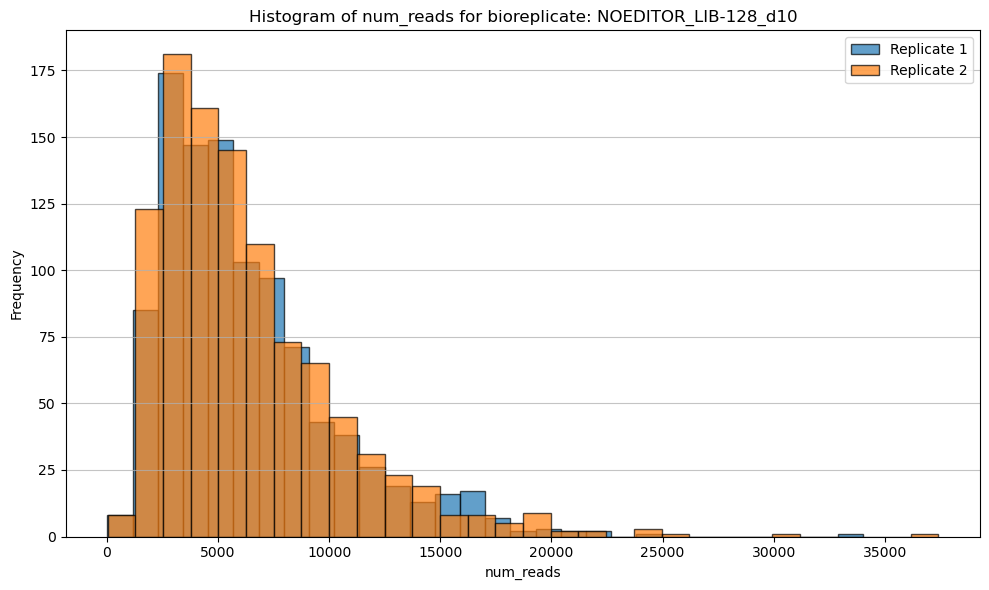

2
NOEDITOR_LIB-130_d10 1 6569480 5340.0
NOEDITOR_LIB-130_d10 1 7166062 5884.0


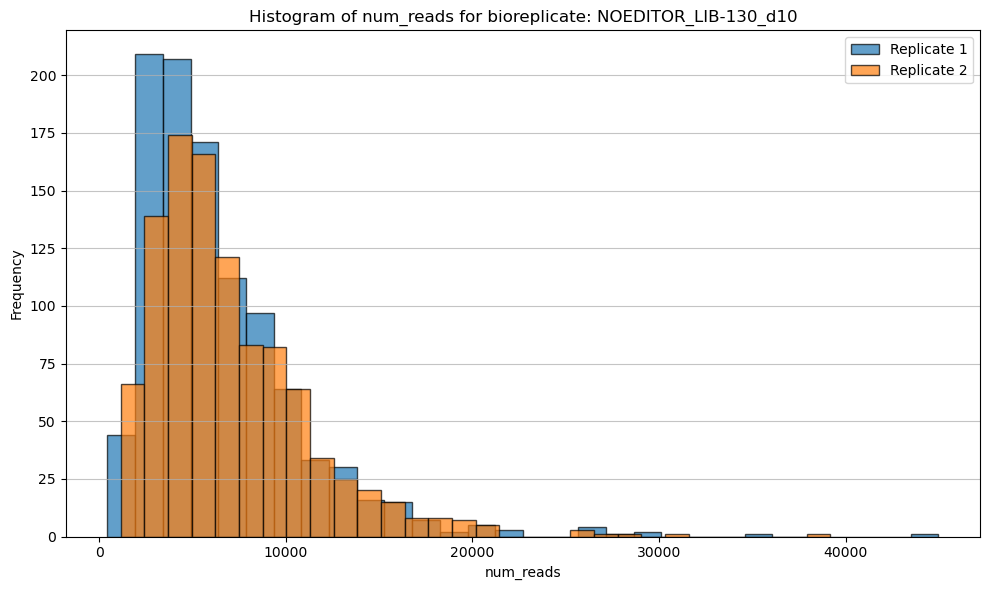

2
NOEDITOR_LIB-132_d10 1 7778026 6593.5
NOEDITOR_LIB-132_d10 1 7778968 6625.0


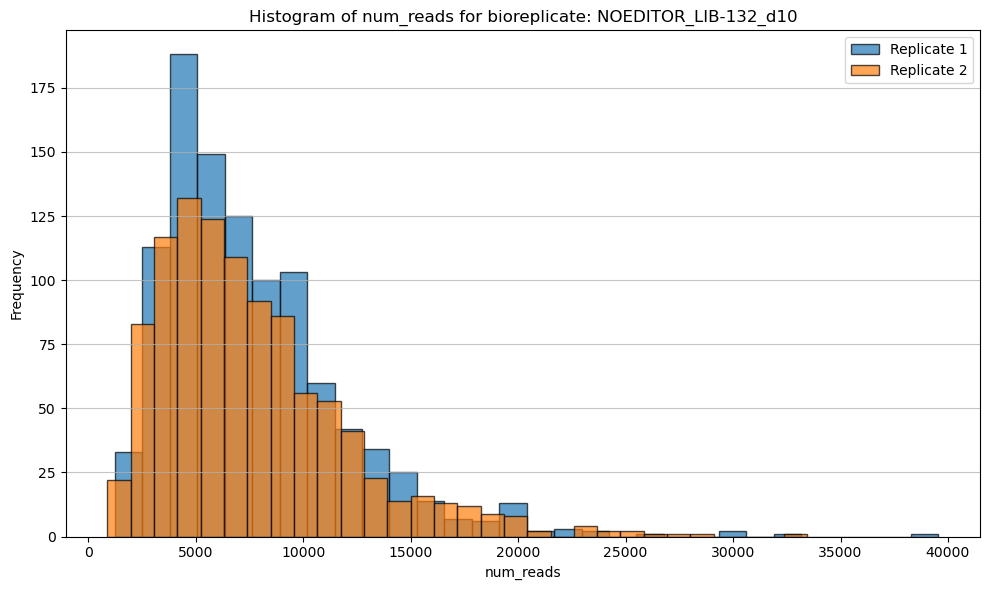

2
TnpB-Var1-140_ABE_LIB-128_d10 1 7583074 5991.0
TnpB-Var1-140_ABE_LIB-128_d10 1 7057798 5728.0


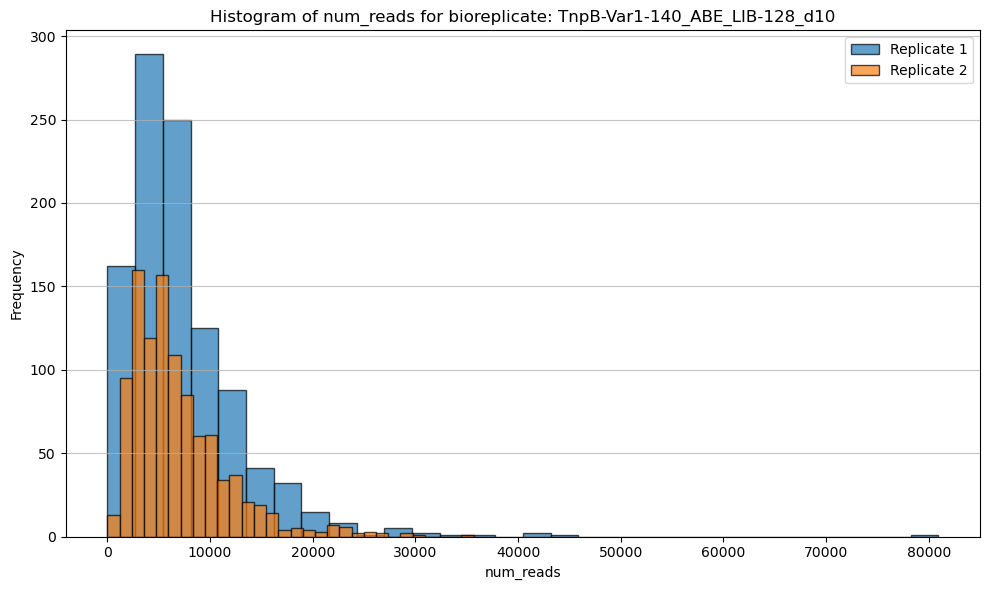

2
TnpB-Var1-140_ABE_LIB-130_d10 1 7365470 6120.0
TnpB-Var1-140_ABE_LIB-130_d10 1 6712239 5549.0


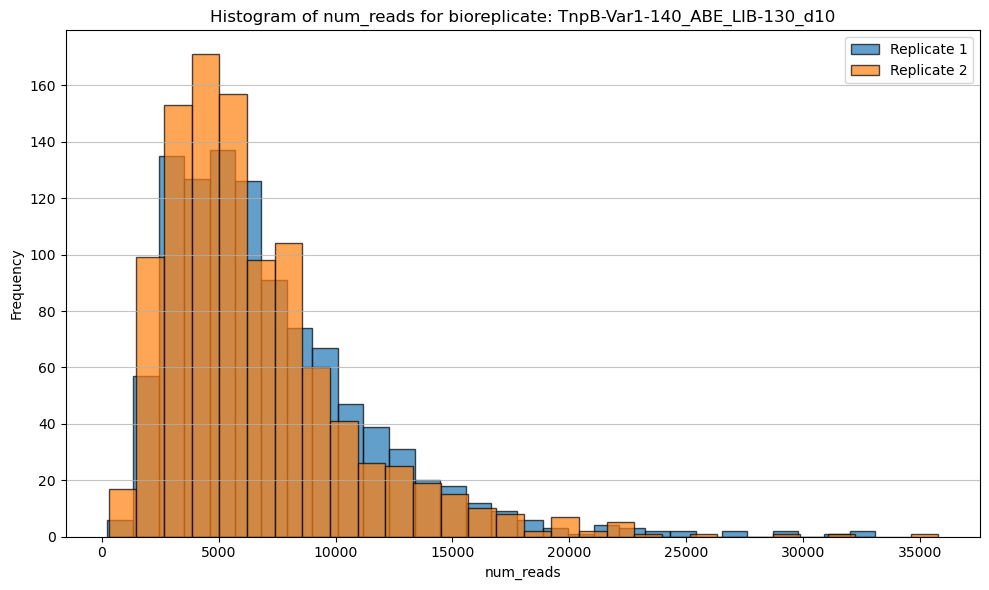

2
TnpB-Var1-140_ABE_LIB-132_d10 1 5818790 4924.5
TnpB-Var1-140_ABE_LIB-132_d10 1 5649709 4824.0


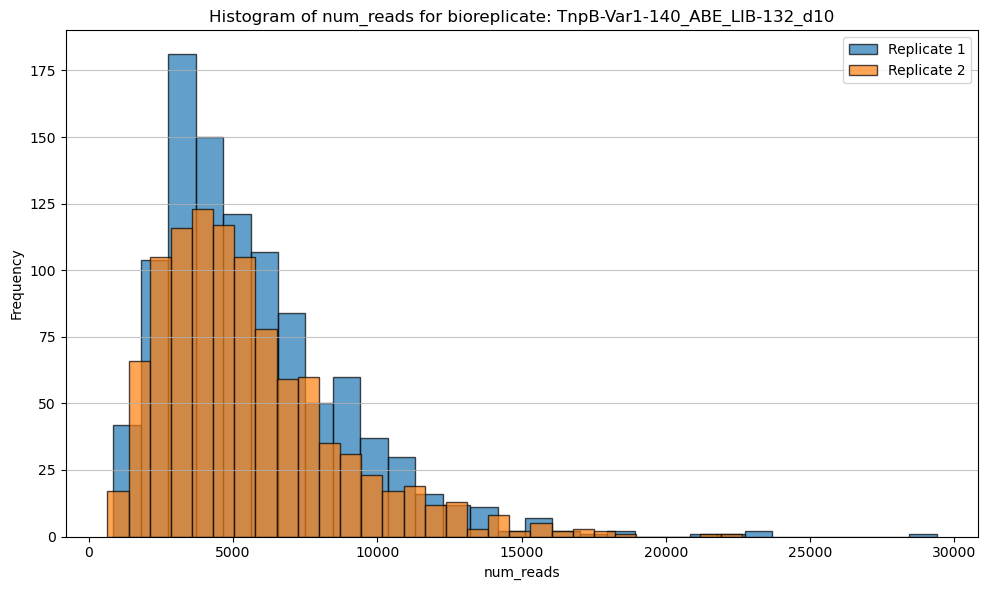

2
TnpB-Var2-163_ABE_LIB-128_d10 1 5833349 4599.0
TnpB-Var2-163_ABE_LIB-128_d10 1 6351263 5026.0


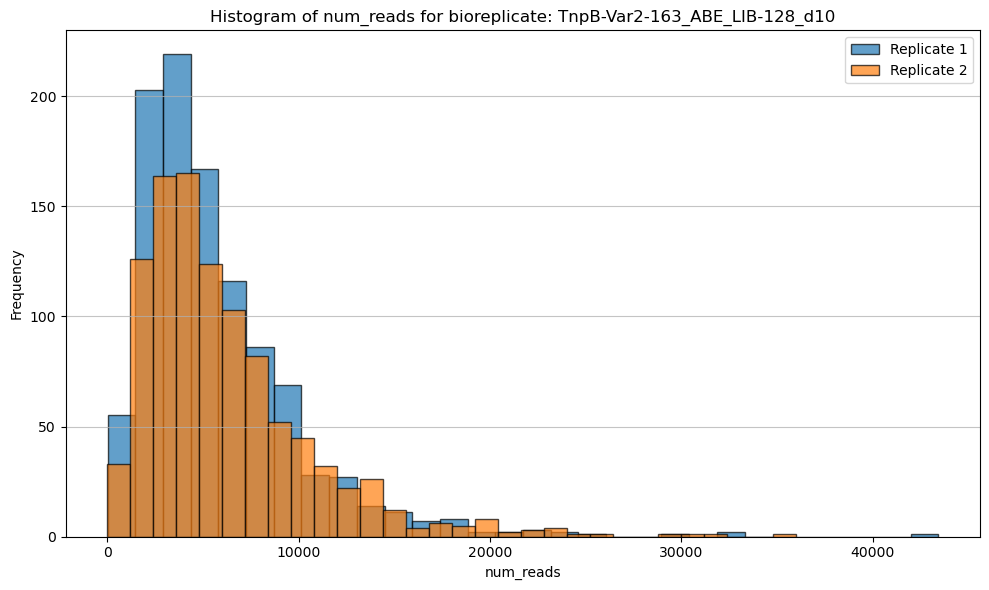

2
TnpB-Var2-163_ABE_LIB-130_d10 1 7099609 5670.5
TnpB-Var2-163_ABE_LIB-130_d10 1 4770790 3911.5


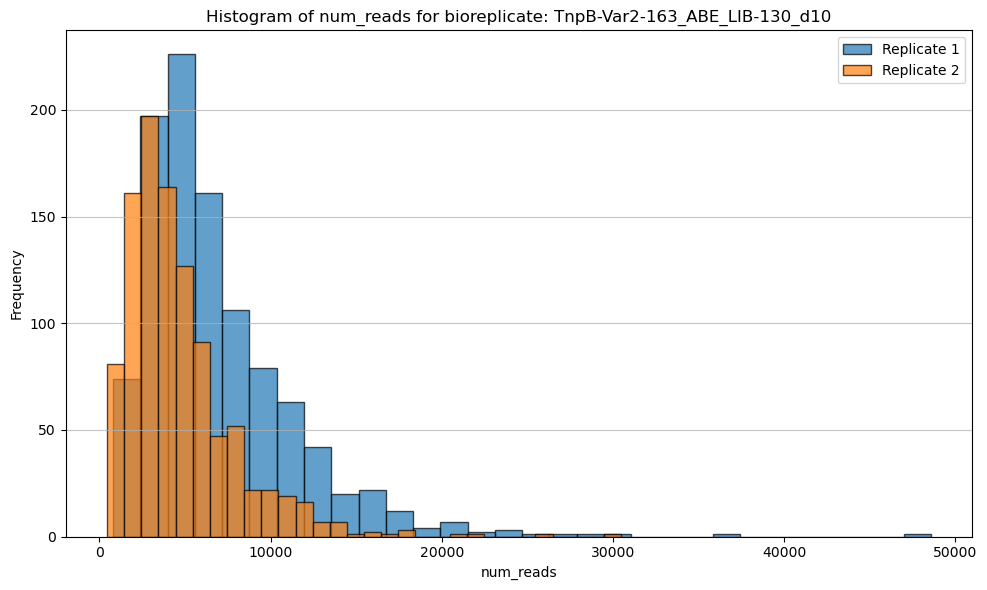

2
TnpB-Var2-163_ABE_LIB-132_d10 1 7488828 6247.0
TnpB-Var2-163_ABE_LIB-132_d10 1 6722792 5565.0


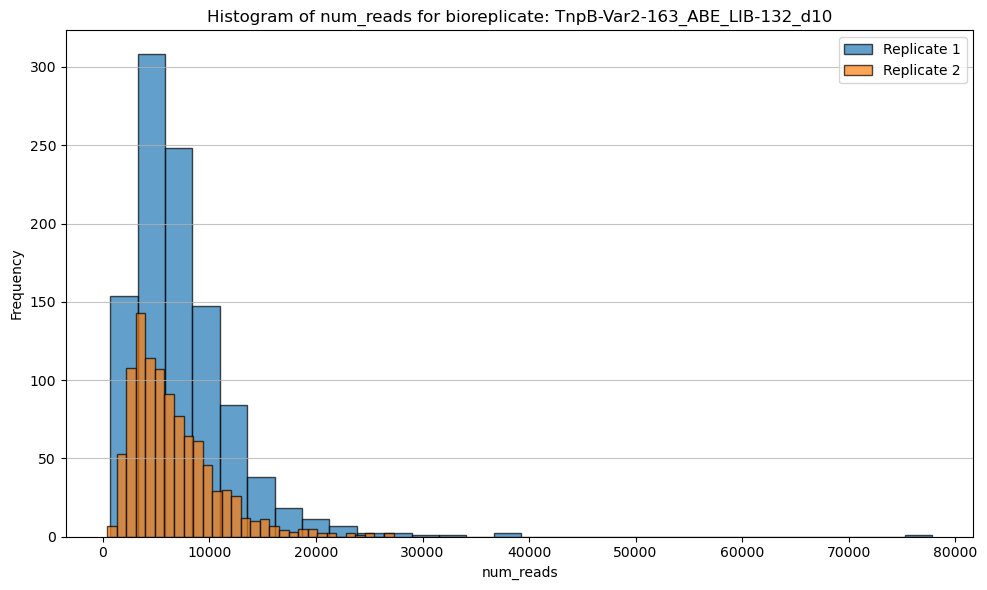

2
TnpB-Var3-164_ABE_LIB-128_d10 1 5375107 4332.5
TnpB-Var3-164_ABE_LIB-128_d10 1 4971069 3972.5


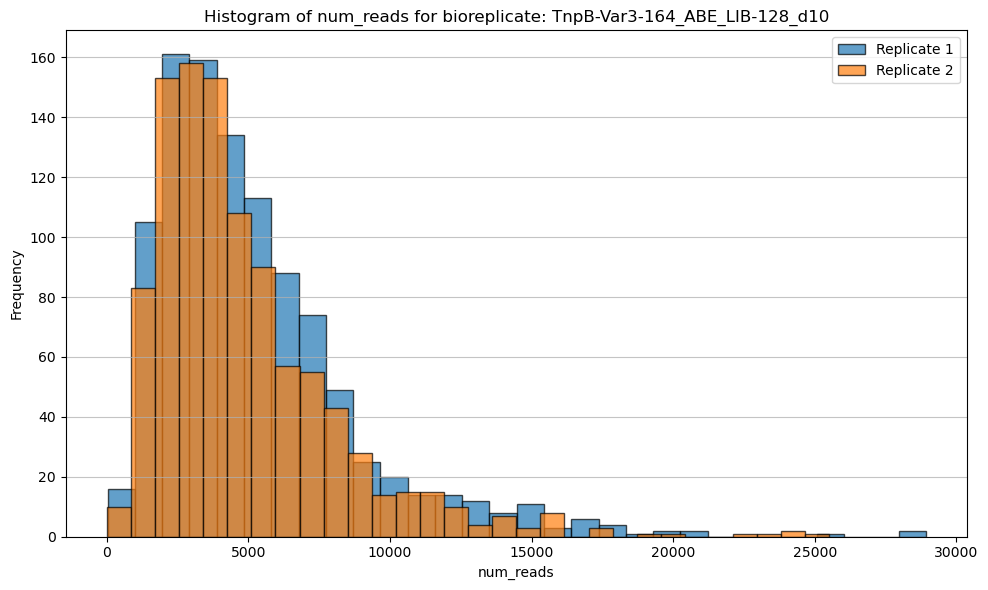

2
TnpB-Var3-164_ABE_LIB-130_d10 1 6951370 5721.0
TnpB-Var3-164_ABE_LIB-130_d10 1 8308188 6836.5


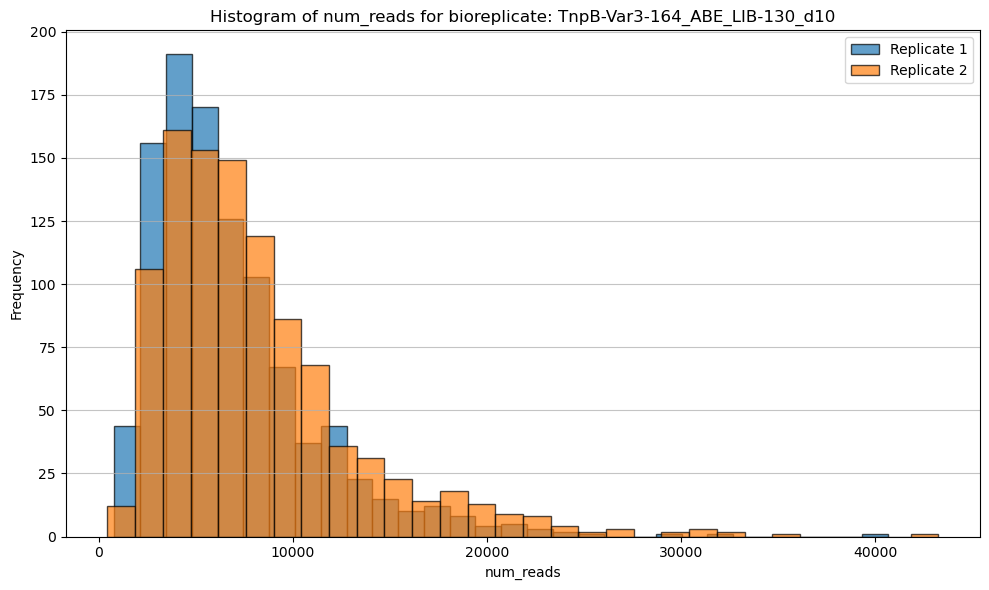

2
TnpB-Var3-164_ABE_LIB-132_d10 1 7449397 6391.5
TnpB-Var3-164_ABE_LIB-132_d10 1 7113636 6126.0


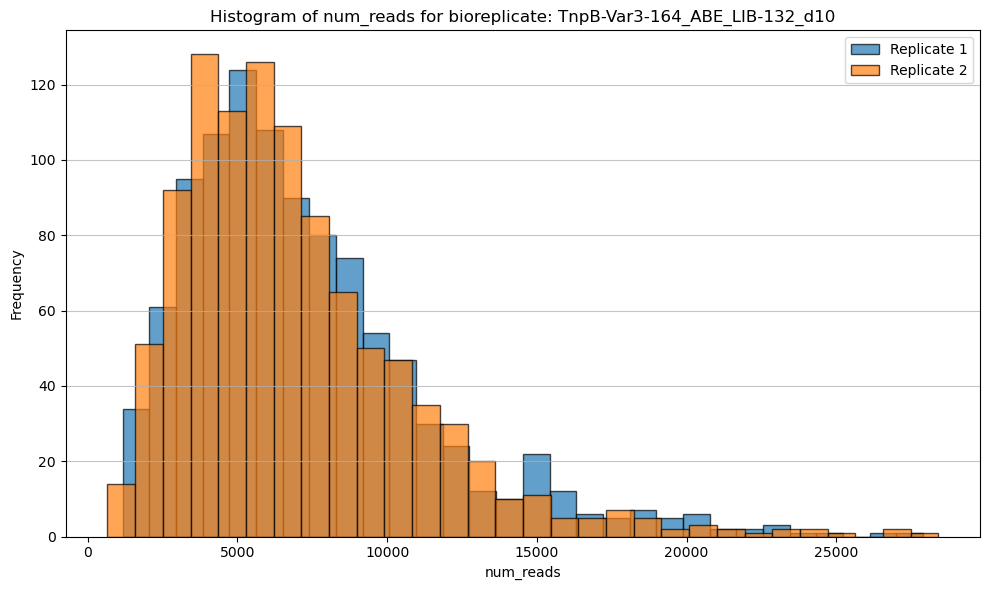

2
TnpB-WT_ABE_LIB-128_d10 1 7824262 6196.5
TnpB-WT_ABE_LIB-128_d10 1 7077046 5622.5


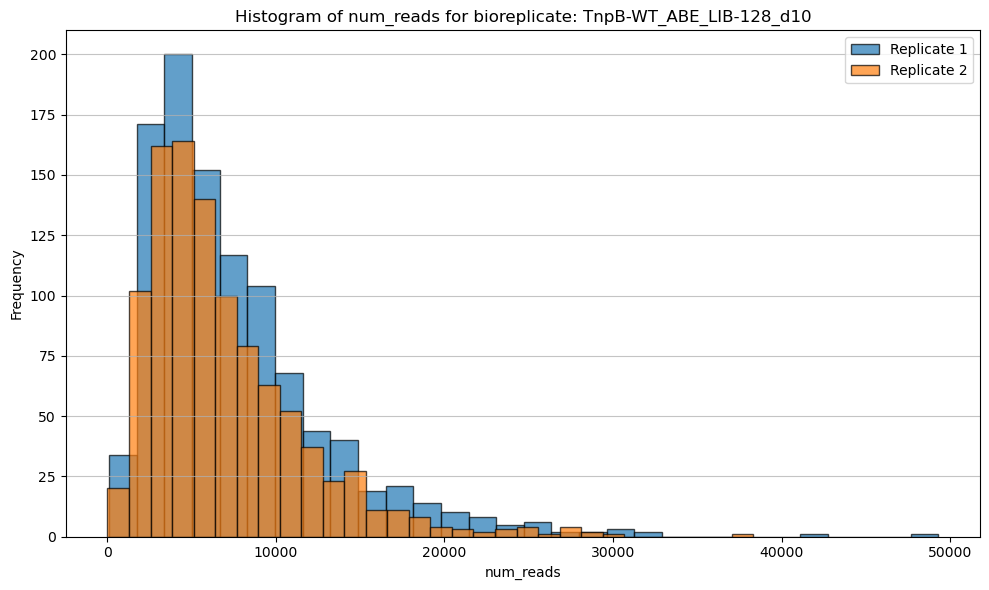

2
TnpB-WT_ABE_LIB-130_d10 1 6880025 5608.5
TnpB-WT_ABE_LIB-130_d10 1 7444919 6080.5


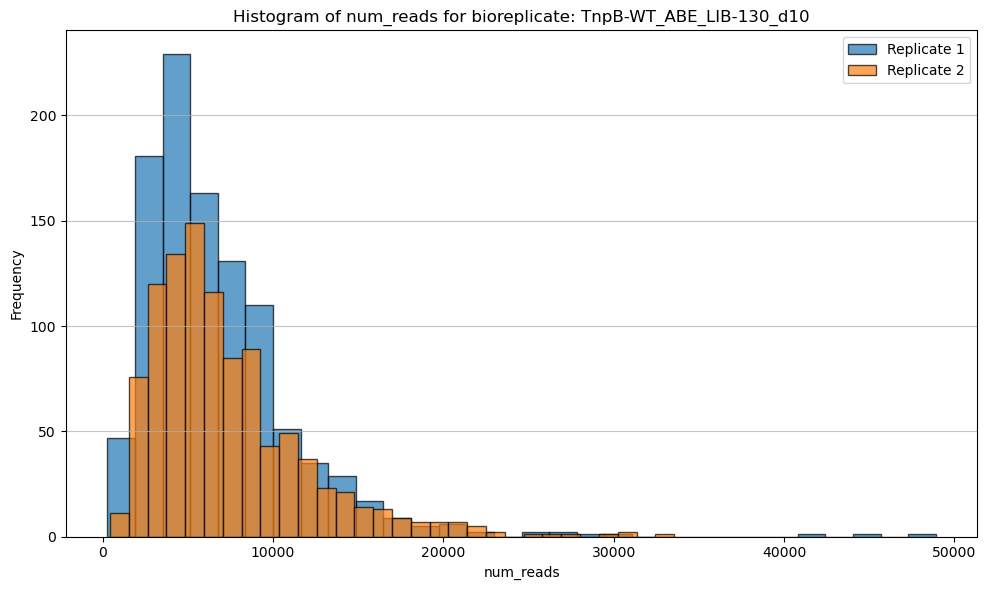

2
TnpB-WT_ABE_LIB-132_d10 1 6509679 5428.5
TnpB-WT_ABE_LIB-132_d10 1 6808218 5745.0


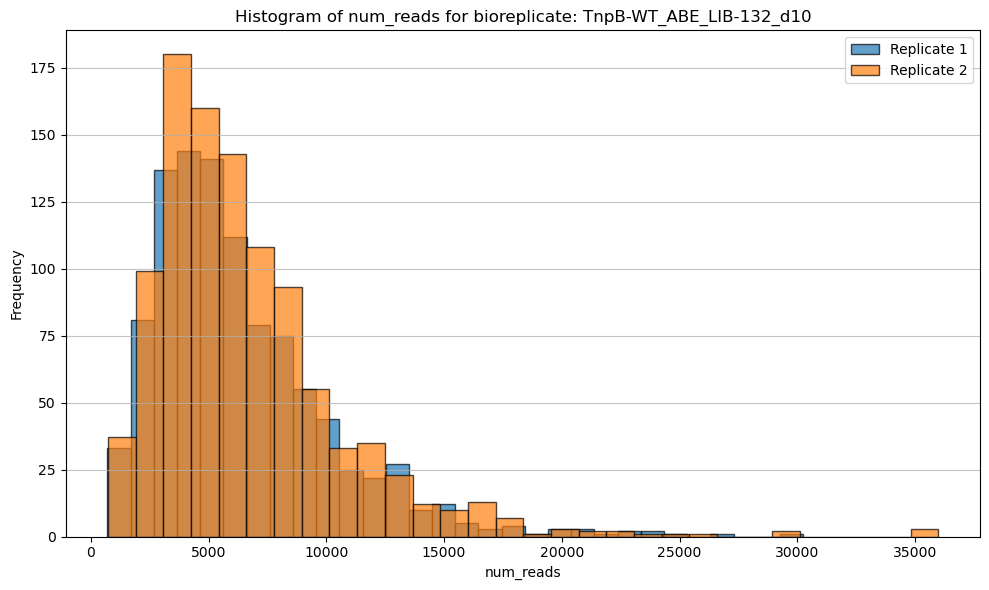

In [23]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

import matplotlib.pyplot as plt

# Group by 'bioreplicate' and then by 'replicate' to plot histograms
for bioreplicate, bioreplicate_group in all_abe_samples_reads_editedrates_unfiltered_not_normalized.groupby('bioreplicate'):
    print(len(bioreplicate_group['replicate'].unique()))

    fig, ax = plt.subplots(figsize=(10, 6))
    colors = plt.cm.tab10.colors  # Use a colormap for different colors
    for i, (replicate, replicate_group) in enumerate(bioreplicate_group.groupby('replicate')):
        print(bioreplicate,replicate_group.loc[:,"spacer"].nunique(),replicate_group['num_reads'].sum(),replicate_group['num_reads'].median())

        # spacer_counts = replicate_group.groupby('spacer').size()
        # print("Spacer counts per group:")
        # print(spacer_counts)

        # spacer_sum = replicate_group.groupby('spacer')['num_reads'].sum()
        # print("Sum of num_reads per spacer:")
        # print(spacer_sum)

        ax.hist(replicate_group['num_reads'], bins=30, alpha=0.7, color=colors[i % len(colors)], edgecolor='black', label=f'Replicate {replicate}')
    ax.set_title(f'Histogram of num_reads for bioreplicate: {bioreplicate}')
    ax.set_xlabel('num_reads')
    ax.set_ylabel('Frequency')
    #ax.set_yscale('log')
    #ax.set_xlim(0, 1000)
    #ax.set_xscale('log')
    ax.grid(axis='y', alpha=0.75)
    ax.legend()
    plt.tight_layout()
    plt.show()

In [24]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

all_abe_samples_reads_editedrates_not_normalized=all_abe_samples_reads_editedrates_unfiltered_not_normalized.\
    loc[all_abe_samples_reads_editedrates_unfiltered_not_normalized['num_reads'] >= 100]     # 100,
print(all_abe_samples_reads_editedrates_not_normalized.shape)

(30711, 14)


In [25]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

all_abe_samples_reads_editedrates_not_normalized_pivot_df = all_abe_samples_reads_editedrates_not_normalized.pivot_table(index=['spacer', 'TAM', "target_site_lib"],
                                           columns='sample_name',
                                           values=['frac_reads_edited','num_reads'],  # values='edit_rate',
                                            aggfunc='first'
                                           ).reset_index()

all_abe_samples_reads_editedrates_not_normalized_pivot_df.columns = ['_'.join(col).strip() for col in all_abe_samples_reads_editedrates_not_normalized_pivot_df.columns.values]

print(all_abe_samples_reads_editedrates_not_normalized_pivot_df.shape)
all_abe_samples_reads_editedrates_not_normalized_pivot_df

(3072, 63)


,spacer_,TAM_,target_site_lib_,frac_reads_edited_NOEDITOR_LIB-128_d10_rep1,frac_reads_edited_NOEDITOR_LIB-128_d10_rep2,frac_reads_edited_NOEDITOR_LIB-130_d10_rep1,frac_reads_edited_NOEDITOR_LIB-130_d10_rep2,frac_reads_edited_NOEDITOR_LIB-132_d10_rep1,frac_reads_edited_NOEDITOR_LIB-132_d10_rep2,frac_reads_edited_TnpB-Var1-140_ABE_LIB-128_d10_rep1,...,num_reads_TnpB-Var3-164_ABE_LIB-130_d10_rep1,num_reads_TnpB-Var3-164_ABE_LIB-130_d10_rep2,num_reads_TnpB-Var3-164_ABE_LIB-132_d10_rep1,num_reads_TnpB-Var3-164_ABE_LIB-132_d10_rep2,num_reads_TnpB-WT_ABE_LIB-128_d10_rep1,num_reads_TnpB-WT_ABE_LIB-128_d10_rep2,num_reads_TnpB-WT_ABE_LIB-130_d10_rep1,num_reads_TnpB-WT_ABE_LIB-130_d10_rep2,num_reads_TnpB-WT_ABE_LIB-132_d10_rep1,num_reads_TnpB-WT_ABE_LIB-132_d10_rep2
0,ATACTGTAAAGAAGCAGAAA,AAAAA,ATACTGTAAAGAAGCAGAAA,NaN,NaN,NaN,NaN,0.044414,0.178601,NaN,...,NaN,NaN,7481.0,7040.0,NaN,NaN,NaN,NaN,7084.0,6396.0
1,ATACTGTAAAGAAGCAGAAA,AAAAC,ATACTGTAAAGAAGCAGAAA,NaN,NaN,NaN,NaN,0.067039,0.146124,NaN,...,NaN,NaN,3769.0,4319.0,NaN,NaN,NaN,NaN,1636.0,3288.0
2,ATACTGTAAAGAAGCAGAAA,AAAAG,ATACTGTAAAGAAGCAGAAA,NaN,NaN,NaN,NaN,0.092654,0.117007,NaN,...,NaN,NaN,6517.0,6285.0,NaN,NaN,NaN,NaN,5512.0,2204.0
3,ATACTGTAAAGAAGCAGAAA,AAAAT,ATACTGTAAAGAAGCAGAAA,NaN,NaN,NaN,NaN,0.020220,0.088702,NaN,...,NaN,NaN,7273.0,9928.0,NaN,NaN,NaN,NaN,7109.0,4556.0
4,ATACTGTAAAGAAGCAGAAA,AAACA,ATACTGTAAAGAAGCAGAAA,NaN,NaN,NaN,NaN,0.054684,0.400076,NaN,...,NaN,NaN,10789.0,11181.0,NaN,NaN,NaN,NaN,4715.0,3524.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3067,TATTATATATGAGTTCACTG,TTTGT,TATTATATATGAGTTCACTG,NaN,NaN,0.136267,0.230312,NaN,NaN,NaN,...,8295.0,5189.0,NaN,NaN,NaN,NaN,16905.0,7078.0,NaN,NaN
3068,TATTATATATGAGTTCACTG,TTTTA,TATTATATATGAGTTCACTG,NaN,NaN,0.478353,0.259836,NaN,NaN,NaN,...,4814.0,7637.0,NaN,NaN,NaN,NaN,7636.0,2499.0,NaN,NaN
3069,TATTATATATGAGTTCACTG,TTTTC,TATTATATATGAGTTCACTG,NaN,NaN,0.012546,0.014615,NaN,NaN,NaN,...,4037.0,4654.0,NaN,NaN,NaN,NaN,3755.0,3528.0,NaN,NaN
3070,TATTATATATGAGTTCACTG,TTTTG,TATTATATATGAGTTCACTG,NaN,NaN,0.074794,0.026001,NaN,NaN,NaN,...,6267.0,11995.0,NaN,NaN,NaN,NaN,16470.0,7148.0,NaN,NaN


In [26]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

editor_columns=sorted([l for l in all_abe_samples_reads_editedrates_not_normalized_pivot_df.columns if "frac_reads" in l])

all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim=all_abe_samples_reads_editedrates_not_normalized_pivot_df.loc[:,list(editor_columns)]
print(all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim.shape)
all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim

(3072, 30)


,frac_reads_edited_NOEDITOR_LIB-128_d10_rep1,frac_reads_edited_NOEDITOR_LIB-128_d10_rep2,frac_reads_edited_NOEDITOR_LIB-130_d10_rep1,frac_reads_edited_NOEDITOR_LIB-130_d10_rep2,frac_reads_edited_NOEDITOR_LIB-132_d10_rep1,frac_reads_edited_NOEDITOR_LIB-132_d10_rep2,frac_reads_edited_TnpB-Var1-140_ABE_LIB-128_d10_rep1,frac_reads_edited_TnpB-Var1-140_ABE_LIB-128_d10_rep2,frac_reads_edited_TnpB-Var1-140_ABE_LIB-130_d10_rep1,frac_reads_edited_TnpB-Var1-140_ABE_LIB-130_d10_rep2,...,frac_reads_edited_TnpB-Var3-164_ABE_LIB-130_d10_rep1,frac_reads_edited_TnpB-Var3-164_ABE_LIB-130_d10_rep2,frac_reads_edited_TnpB-Var3-164_ABE_LIB-132_d10_rep1,frac_reads_edited_TnpB-Var3-164_ABE_LIB-132_d10_rep2,frac_reads_edited_TnpB-WT_ABE_LIB-128_d10_rep1,frac_reads_edited_TnpB-WT_ABE_LIB-128_d10_rep2,frac_reads_edited_TnpB-WT_ABE_LIB-130_d10_rep1,frac_reads_edited_TnpB-WT_ABE_LIB-130_d10_rep2,frac_reads_edited_TnpB-WT_ABE_LIB-132_d10_rep1,frac_reads_edited_TnpB-WT_ABE_LIB-132_d10_rep2
0,NaN,NaN,NaN,NaN,0.044414,0.178601,NaN,NaN,NaN,NaN,...,NaN,NaN,0.053870,0.067898,NaN,NaN,NaN,NaN,0.069593,0.052846
1,NaN,NaN,NaN,NaN,0.067039,0.146124,NaN,NaN,NaN,NaN,...,NaN,NaN,0.021226,0.020375,NaN,NaN,NaN,NaN,0.029340,0.019161
2,NaN,NaN,NaN,NaN,0.092654,0.117007,NaN,NaN,NaN,NaN,...,NaN,NaN,0.033298,0.342243,NaN,NaN,NaN,NaN,0.080370,0.045826
3,NaN,NaN,NaN,NaN,0.020220,0.088702,NaN,NaN,NaN,NaN,...,NaN,NaN,0.021037,0.087027,NaN,NaN,NaN,NaN,0.038543,0.016462
4,NaN,NaN,NaN,NaN,0.054684,0.400076,NaN,NaN,NaN,NaN,...,NaN,NaN,0.042729,0.079778,NaN,NaN,NaN,NaN,0.081230,0.053065
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3067,NaN,NaN,0.136267,0.230312,NaN,NaN,NaN,NaN,0.032739,0.099422,...,0.053165,0.045481,NaN,NaN,NaN,NaN,0.697190,0.079260,NaN,NaN
3068,NaN,NaN,0.478353,0.259836,NaN,NaN,NaN,NaN,0.368387,0.133356,...,0.129414,0.149273,NaN,NaN,NaN,NaN,0.037454,0.040016,NaN,NaN
3069,NaN,NaN,0.012546,0.014615,NaN,NaN,NaN,NaN,0.016584,0.007913,...,0.014367,0.011818,NaN,NaN,NaN,NaN,0.007190,0.006803,NaN,NaN
3070,NaN,NaN,0.074794,0.026001,NaN,NaN,NaN,NaN,0.028723,0.019417,...,0.097335,0.012672,NaN,NaN,NaN,NaN,0.010686,0.076665,NaN,NaN


(1023, 2)
(1024, 2)
(1024, 2)
(1023, 2)
(1024, 2)
(1024, 2)
(1023, 2)
(1024, 2)
(1024, 2)
(1023, 2)
(1024, 2)
(1024, 2)
(1023, 2)
(1024, 2)
(1024, 2)


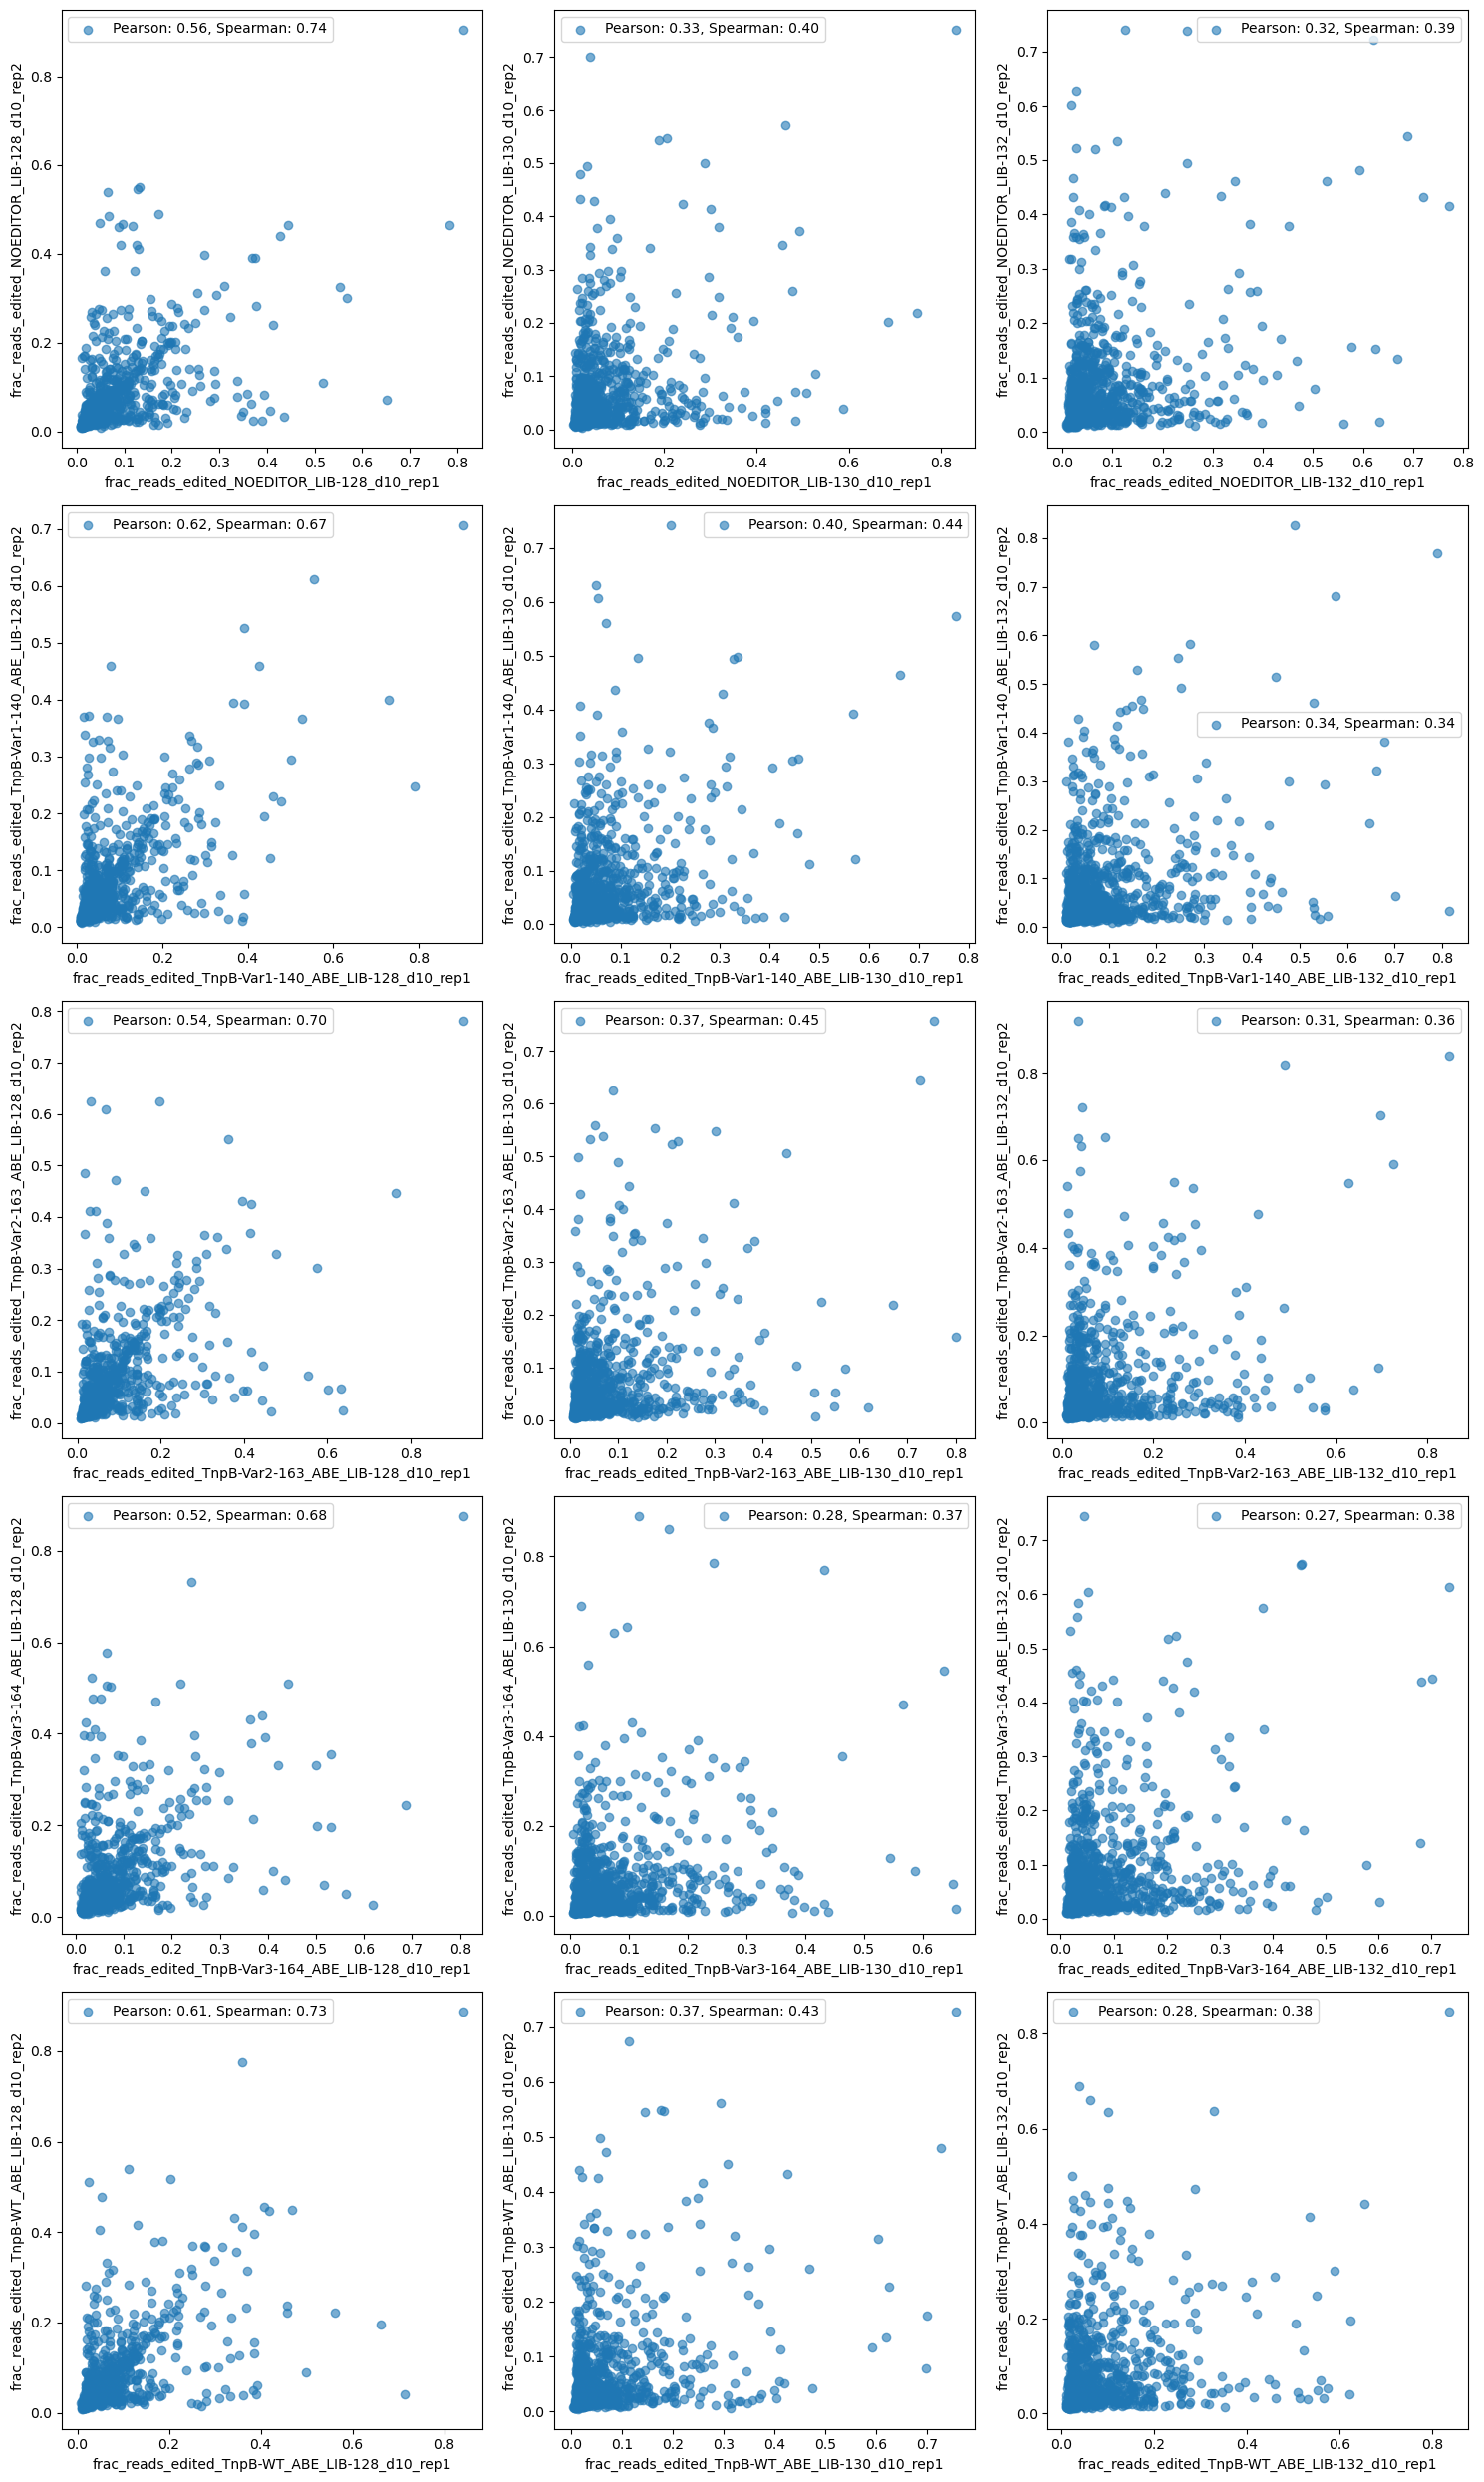

In [27]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

def plot_paired_correlations(df, group_size=6):
    from scipy.stats import pearsonr, spearmanr
    import math
    import matplotlib.pyplot as plt

    cols = list(df.columns)
    n_groups = math.floor(len(cols) / group_size)

    fig, axes = plt.subplots(n_groups, 3, figsize=(15, 5 * n_groups), squeeze=False)

    for i in range(n_groups):
        block = cols[i * group_size : i * group_size + group_size]
        pairs = [(block[0], block[1]), (block[2], block[3]), (block[4], block[5])]
        for j, (col_x, col_y) in enumerate(pairs):
            #data_pair = df[[col_x, col_y]].dropna()
            data_pair = df[[col_x, col_y]].dropna()
            print(data_pair.shape)
            ax = axes[i, j]
            if len(data_pair) > 0:
                p_corr, _ = pearsonr(data_pair[col_x], data_pair[col_y])
                s_corr, _ = spearmanr(data_pair[col_x], data_pair[col_y])
                label = f"Pearson: {p_corr:.2f}, Spearman: {s_corr:.2f}"
            else:
                label = "No data"
            ax.scatter(data_pair[col_x], data_pair[col_y], alpha=0.6, label=label)
            ax.set_xlabel(col_x)
            ax.set_ylabel(col_y)
            ax.legend()

    plt.tight_layout()
    plt.show()

plot_paired_correlations(all_abe_samples_reads_editedrates_not_normalized_pivot_df_slim)

In [28]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

mean_fracs_not_normalized = all_abe_samples_reads_editedrates_not_normalized.groupby(['bioreplicate','TAM', 'spacer'])['frac_reads_edited'].mean().reset_index()
mean_fracs_not_normalized.sort_values(by=['TAM',], inplace=True)
mean_fracs_not_normalized

,bioreplicate,TAM,spacer,frac_reads_edited
0,NOEDITOR_LIB-128_d10,AAAAA,GAAGAGGACCTGGGAGATGA,0.361515
7165,TnpB-Var2-163_ABE_LIB-130_d10,AAAAA,TATTATATATGAGTTCACTG,0.049476
9213,TnpB-Var3-164_ABE_LIB-128_d10,AAAAA,GAAGAGGACCTGGGAGATGA,0.053601
6142,TnpB-Var2-163_ABE_LIB-128_d10,AAAAA,GAAGAGGACCTGGGAGATGA,0.015827
10236,TnpB-Var3-164_ABE_LIB-130_d10,AAAAA,TATTATATATGAGTTCACTG,0.021061
...,...,...,...,...
1022,NOEDITOR_LIB-128_d10,TTTTT,GAAGAGGACCTGGGAGATGA,0.016642
14331,TnpB-WT_ABE_LIB-130_d10,TTTTT,TATTATATATGAGTTCACTG,0.344718
8188,TnpB-Var2-163_ABE_LIB-130_d10,TTTTT,TATTATATATGAGTTCACTG,0.361639
3070,NOEDITOR_LIB-132_d10,TTTTT,ATACTGTAAAGAAGCAGAAA,0.085442


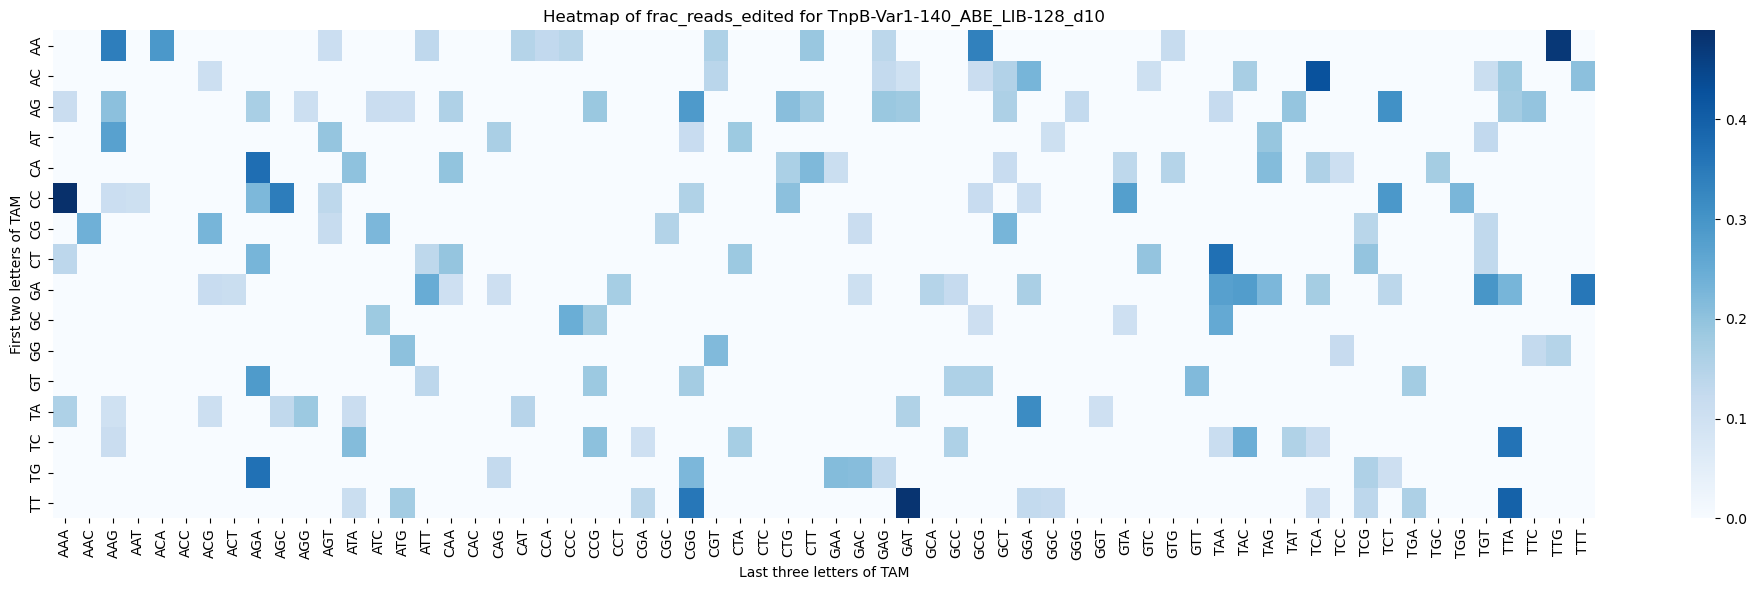

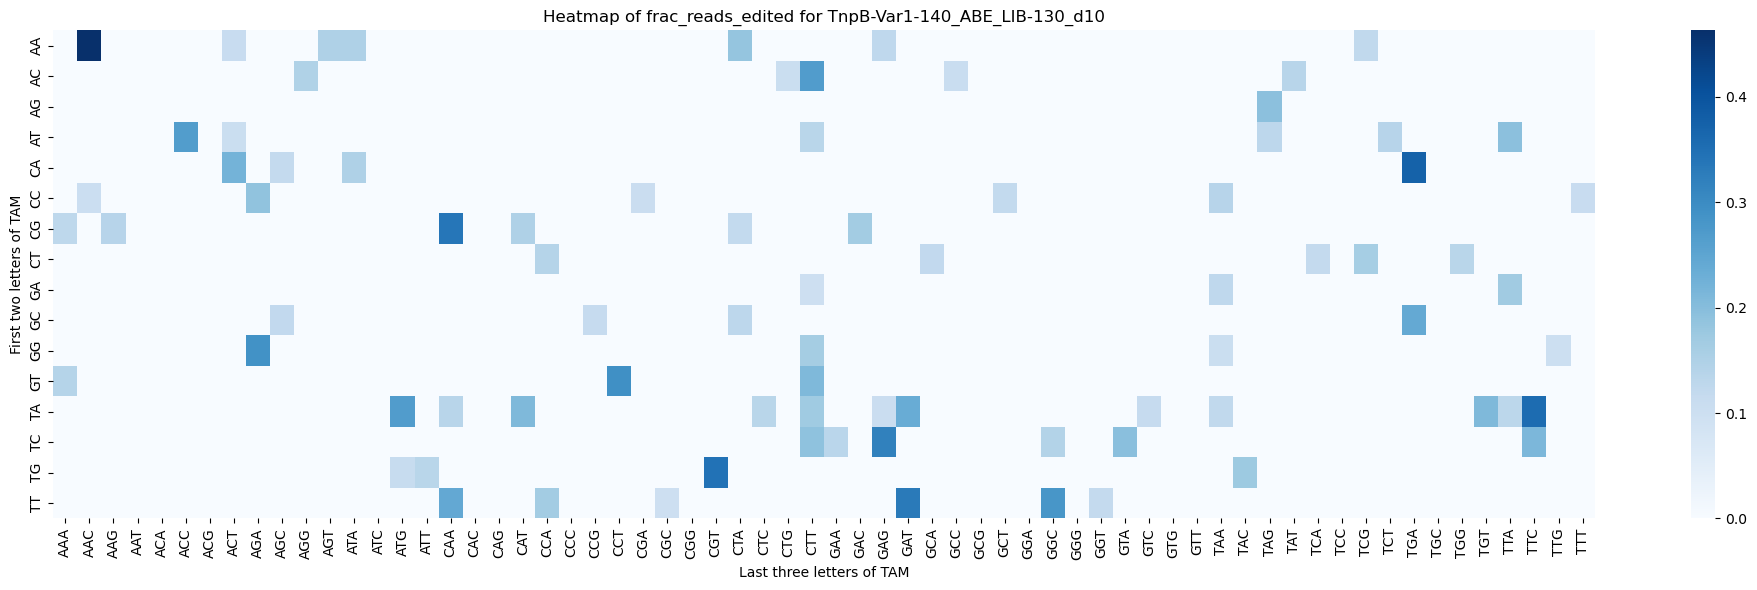

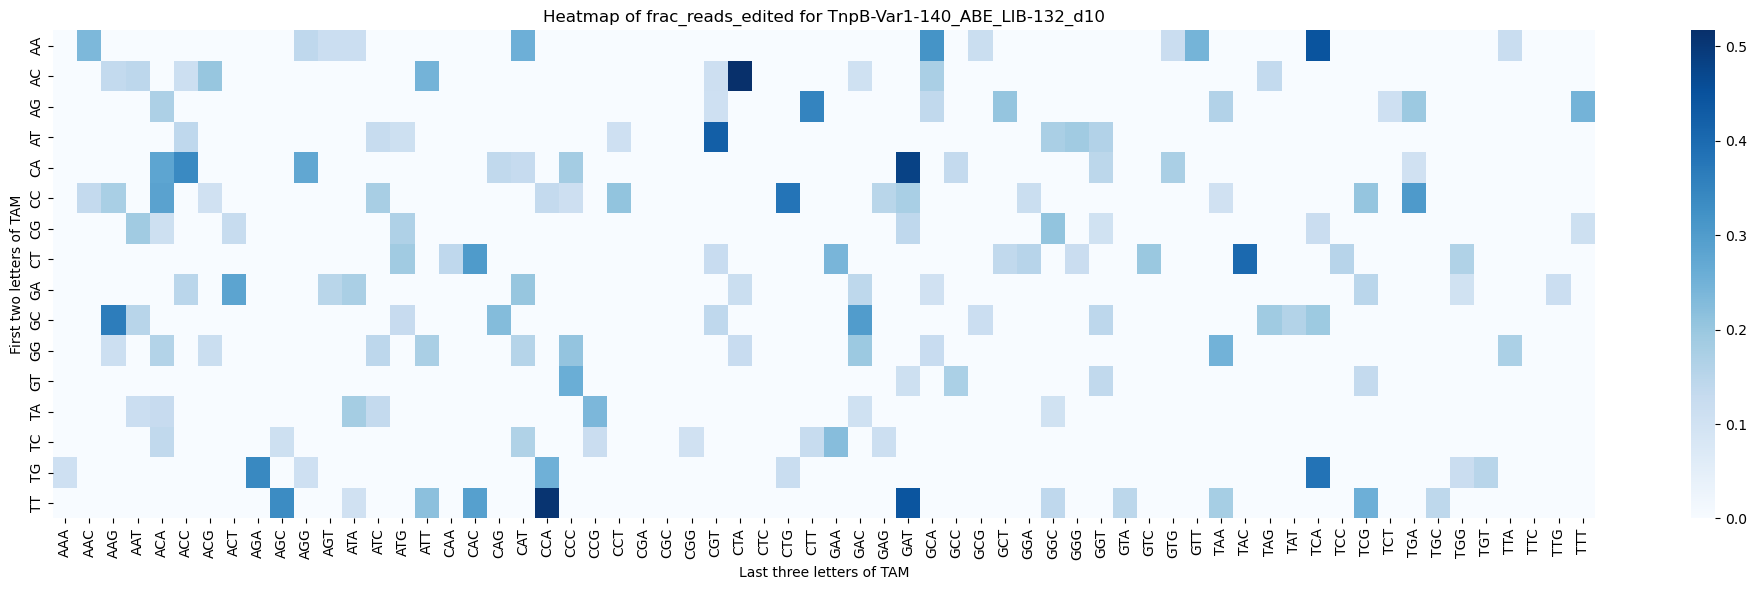

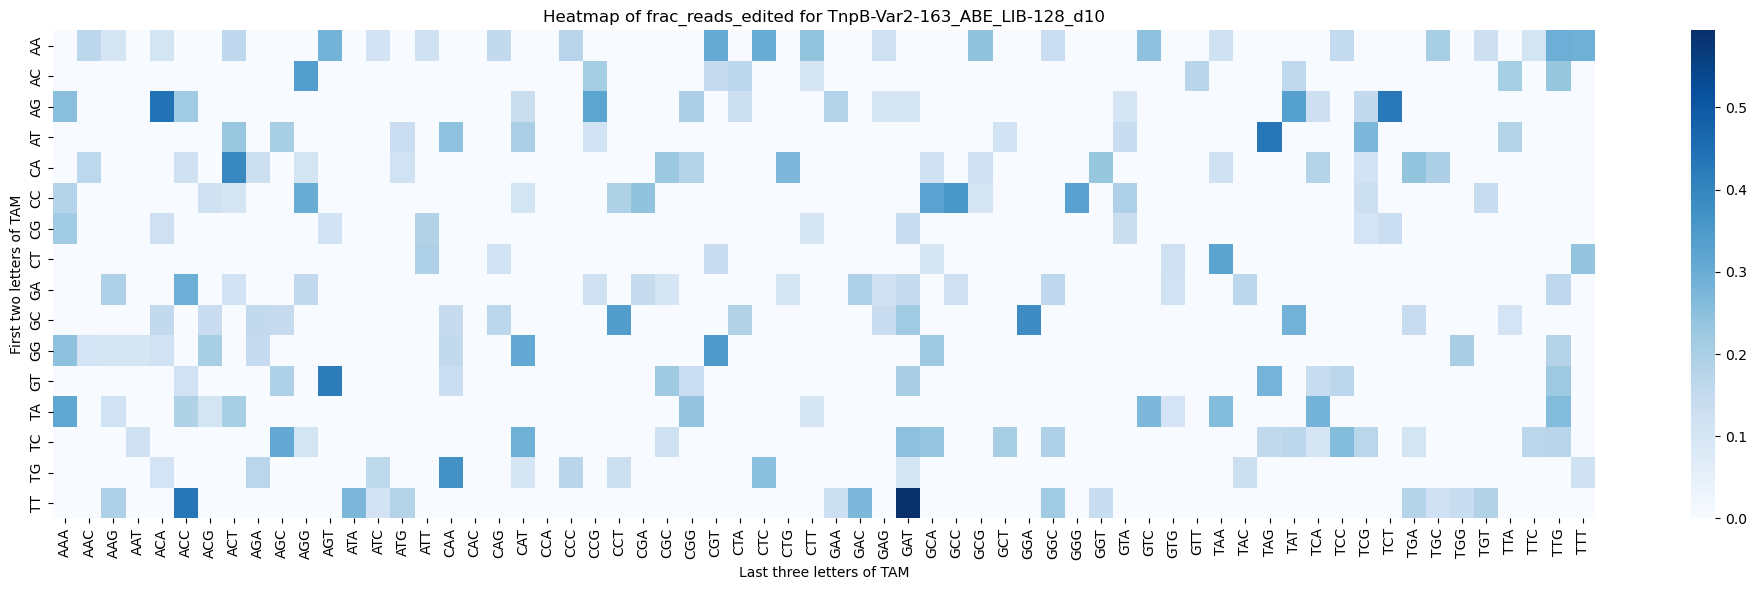

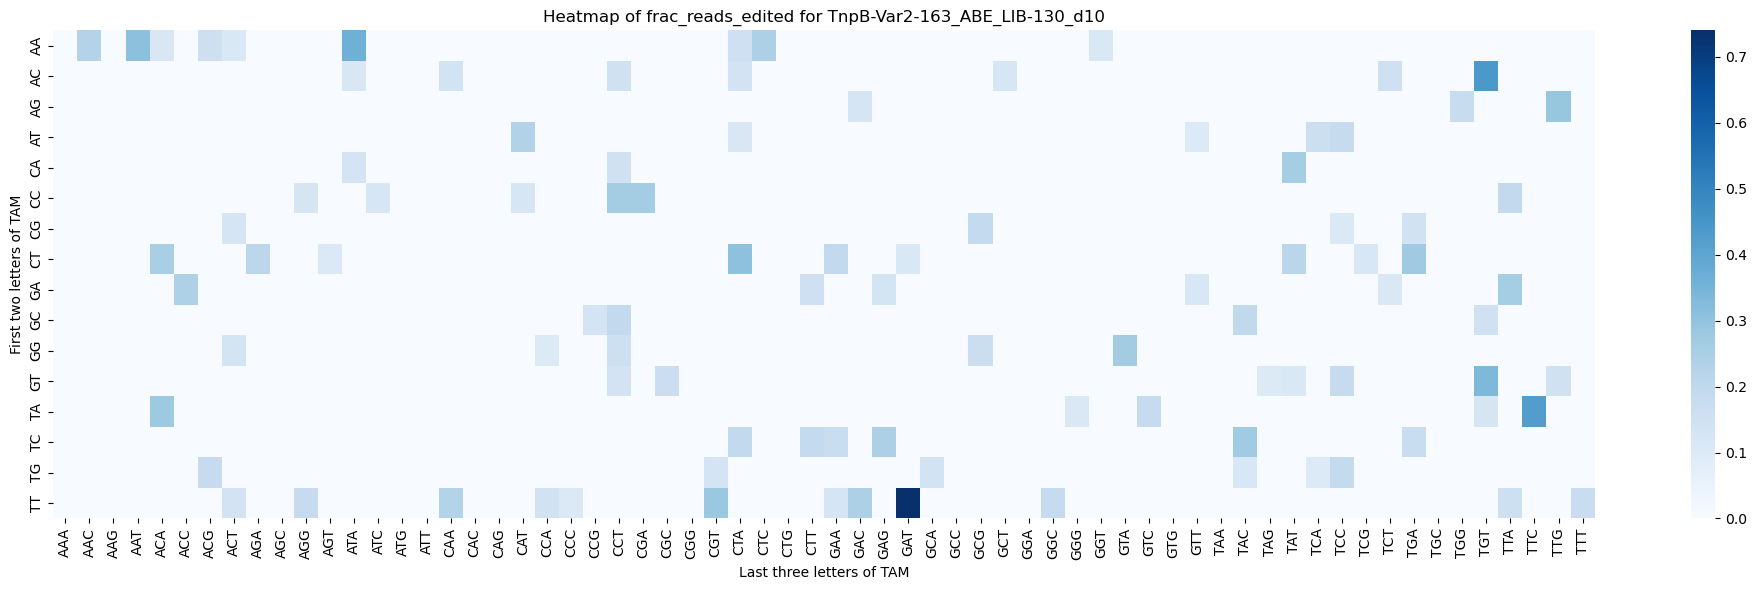

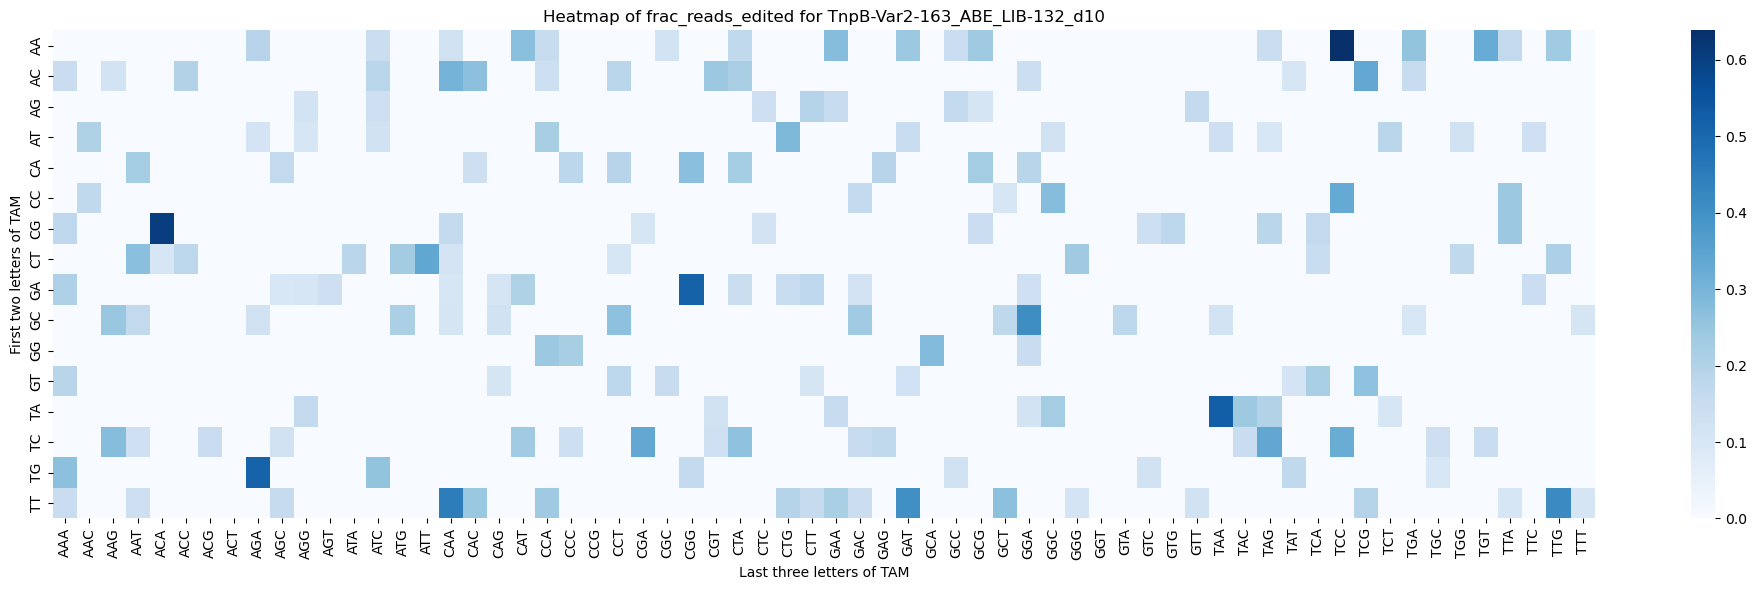

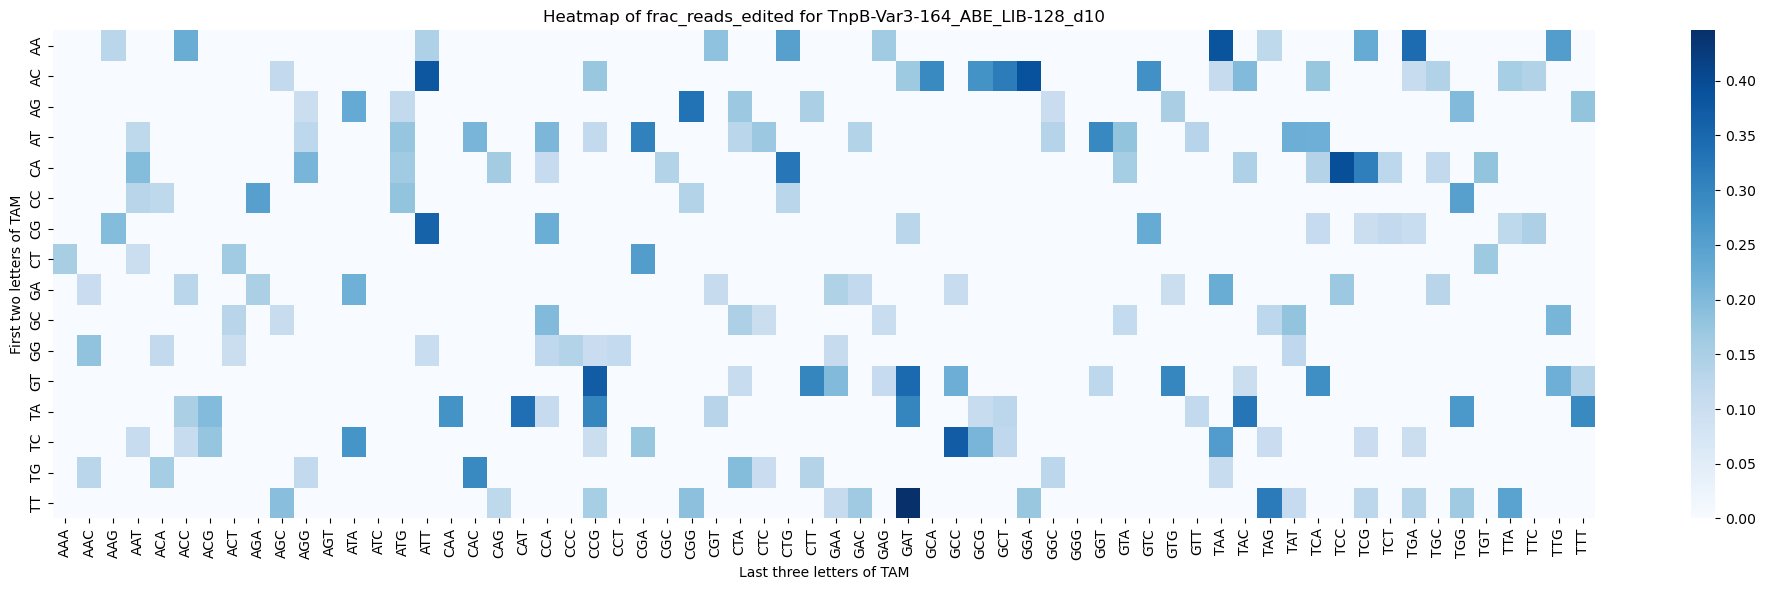

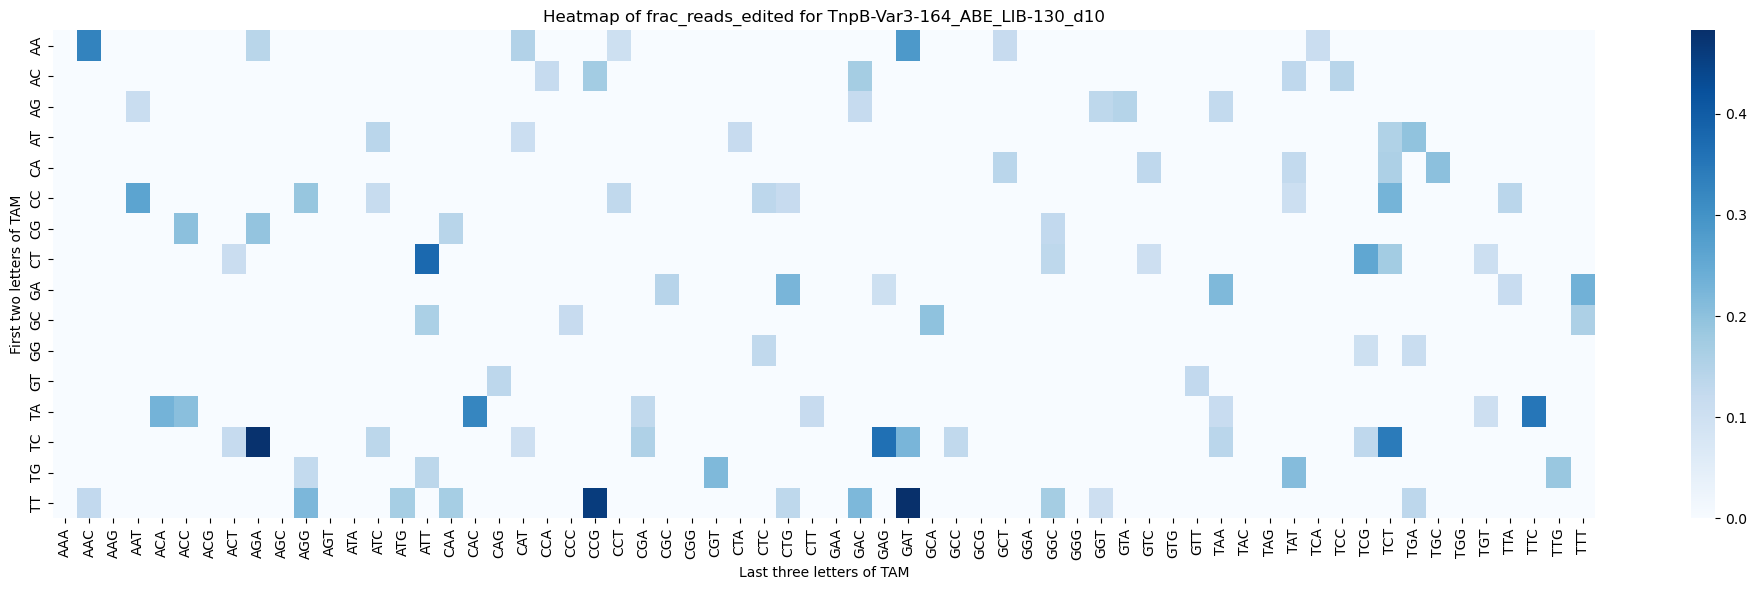

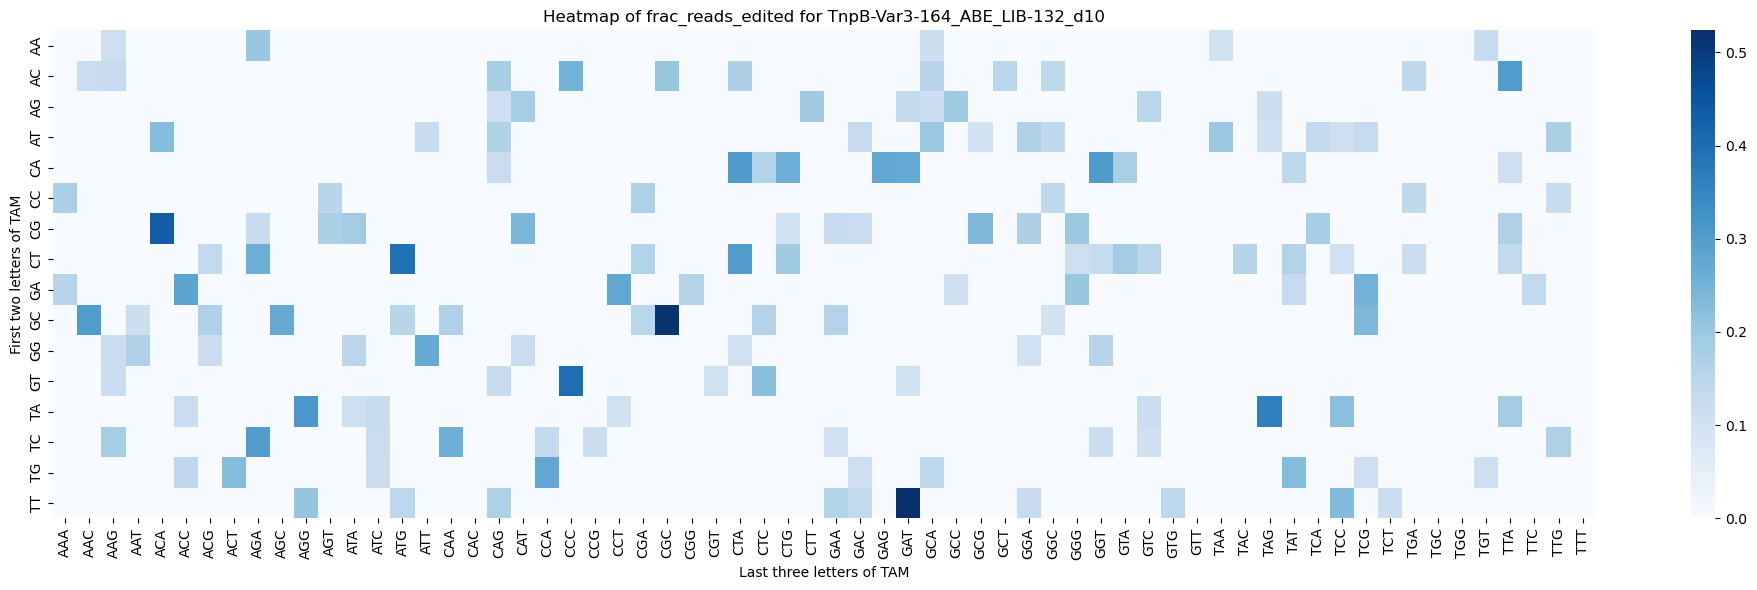

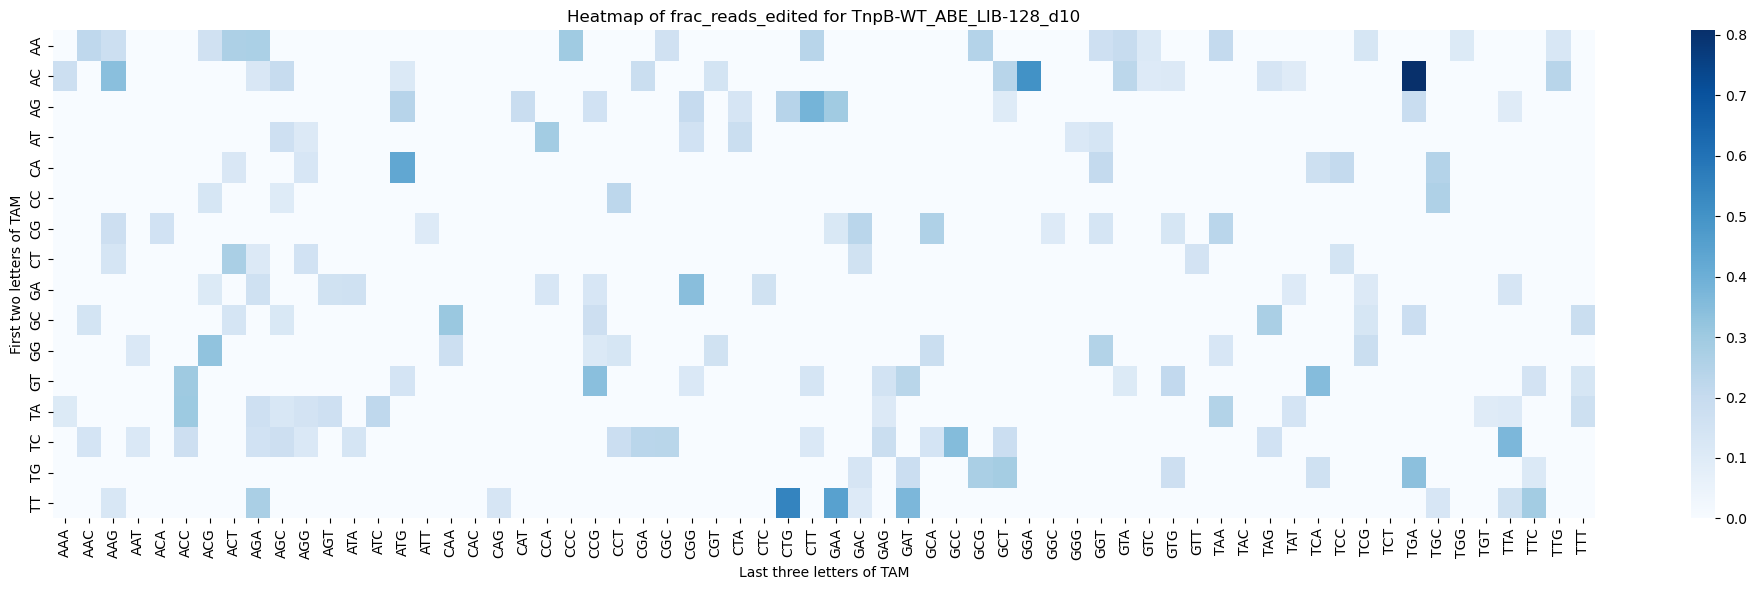

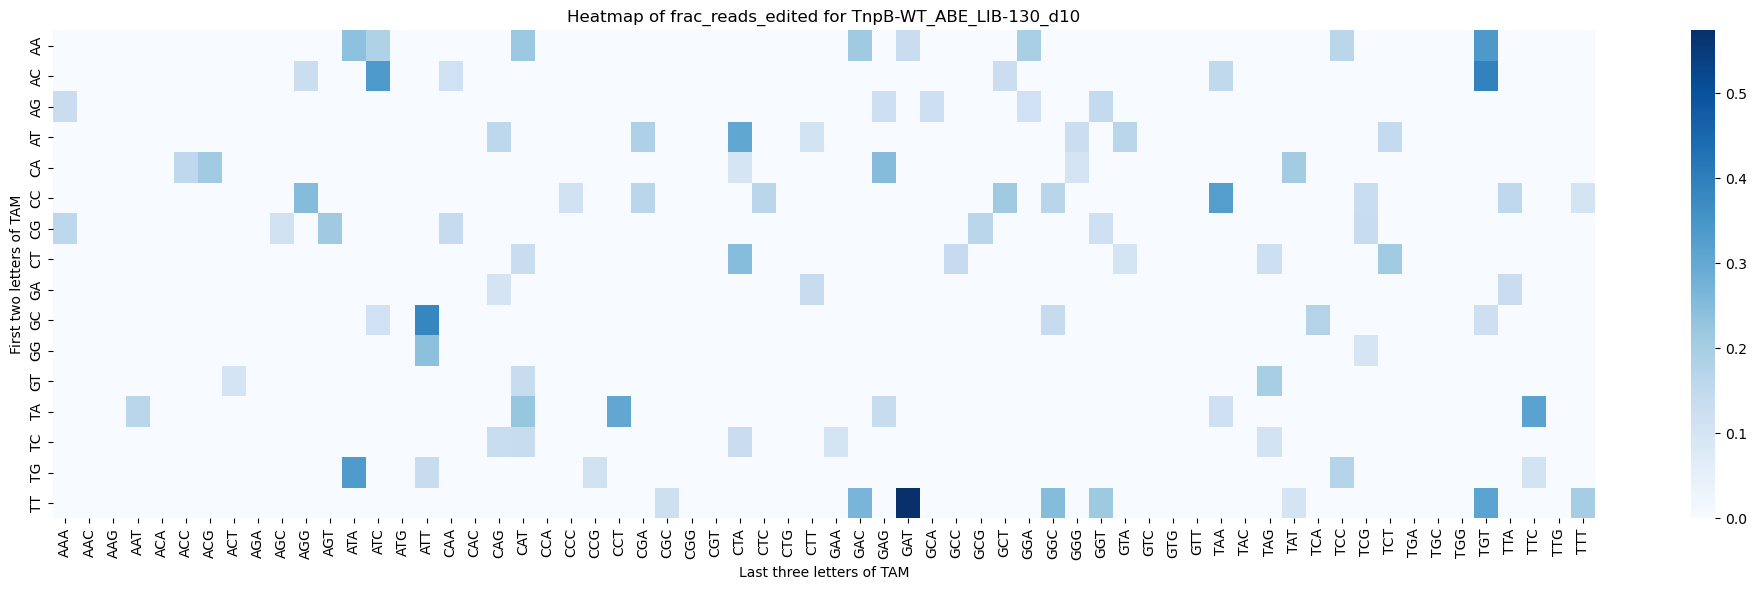

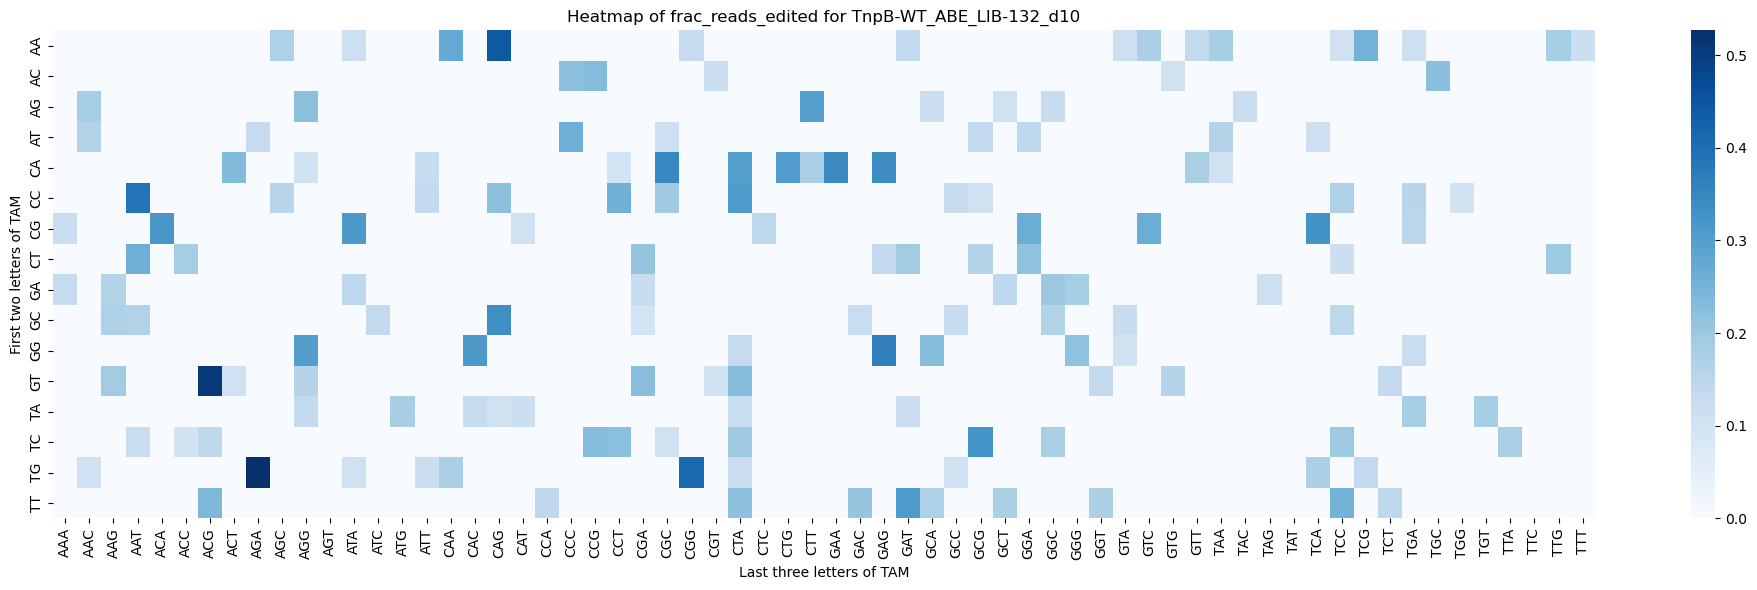

In [29]:
from screening.screen_utils import normalize_editing_rate, normalize_editing_rate_reads

import pandas as pd
def plot_heatmap_for_bioreplicate(mean_fracs, bioreplicate, figsize=(8,6), cmap="viridis"):
    import os
    import seaborn as sns
    import matplotlib.pyplot as plt

    # Filter for the specified bioreplicate and compute heatmap data
    df_heat = mean_fracs[mean_fracs["bioreplicate"] == bioreplicate].copy()
    df_heat.loc[df_heat['frac_reads_edited'] < 0.1, :] = 0
    # Check if all PAMs from config.PAMS are present in df_heat["TAM"]
    missing_pams = set(config.PAMS) - set(df_heat["TAM"].unique())
    if missing_pams:
        # For each missing PAM, add a row with frac_reads_edited set to 0
        df_missing = pd.DataFrame({'TAM': list(missing_pams), 'frac_reads_edited': 0})
        df_heat = pd.concat([df_heat, df_missing], ignore_index=True)
    df_heat["TAM_row"] = df_heat["TAM"].str[:2]
    df_heat["TAM_col"] = df_heat["TAM"].str[-3:]
    pivot_heat = df_heat.pivot_table(index="TAM_row",
                                     columns="TAM_col",
                                     values="frac_reads_edited",
                                     aggfunc="mean").fillna(0)

    # Plot the heatmap
    plt.figure(figsize=figsize)
    sns.heatmap(pivot_heat, fmt=".3f", cmap=cmap)
    plt.title(f"Heatmap of frac_reads_edited for {bioreplicate}")
    plt.ylabel("First two letters of TAM")
    plt.xlabel("Last three letters of TAM")
    plt.tight_layout()

    # Save the figure to NAS_folder
    save_path = os.path.join(NAS_folder, f"heatmap_{bioreplicate}.png")
    plt.savefig(save_path)
    plt.show()

NAS_folder = "/mnt/G_Pharma/Users/tfang/Cell_Screen/Priscilla_A9_Screen"
os.makedirs(NAS_folder, exist_ok=True)
mean_fracs=pd.read_csv(NAS_folder + "/mean_fracs.csv", index_col=None)
mean_fracs

vis_bioreplicates=sorted(mean_fracs.bioreplicate.unique())
for bioreplicate in vis_bioreplicates:
    plot_heatmap_for_bioreplicate(mean_fracs, bioreplicate, figsize=(20,6), cmap="Blues")

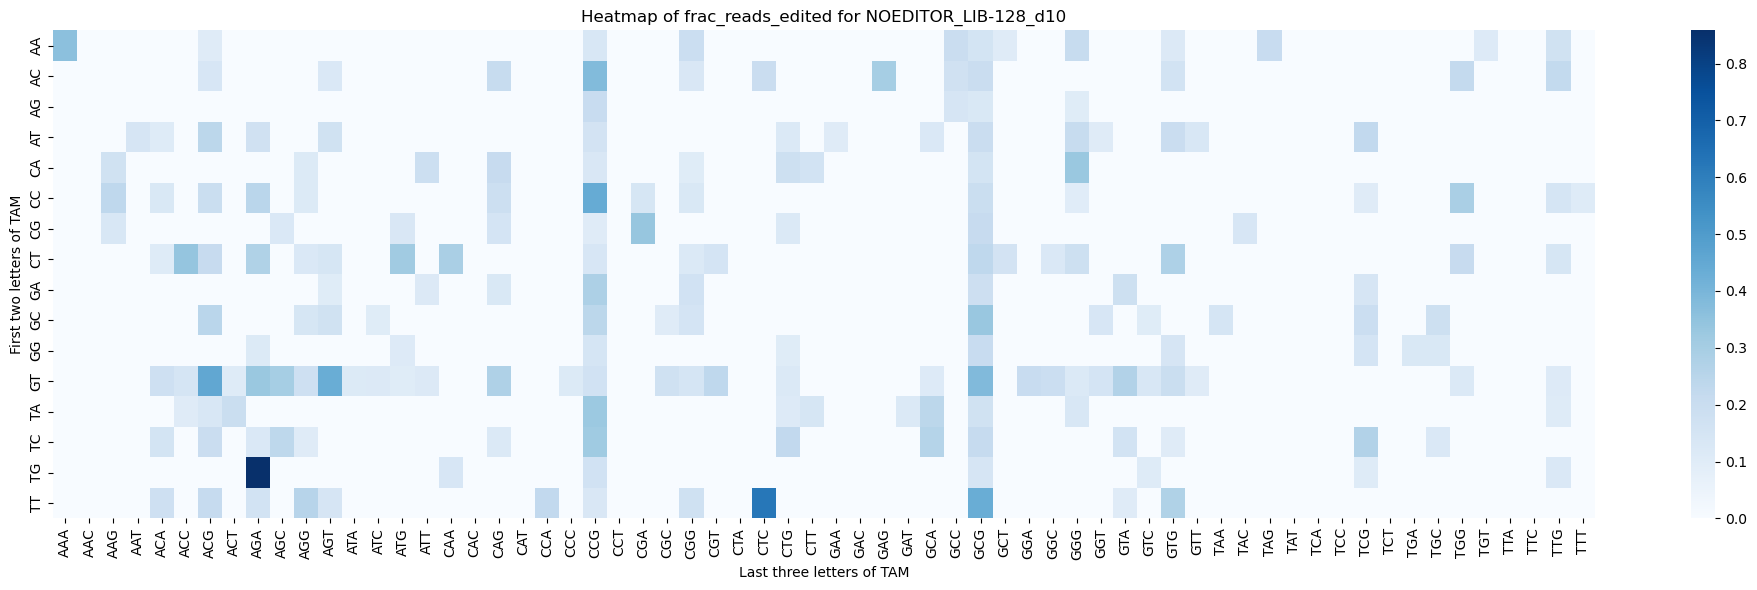

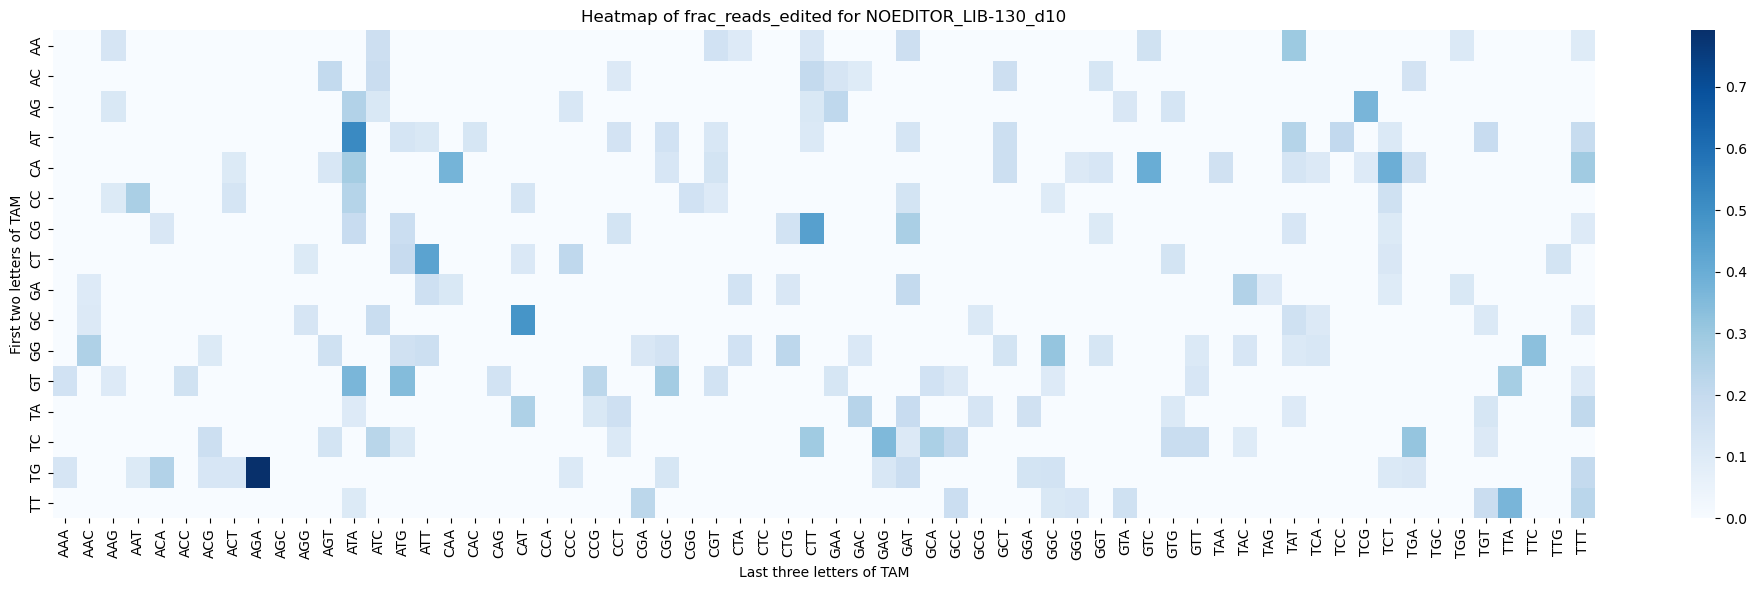

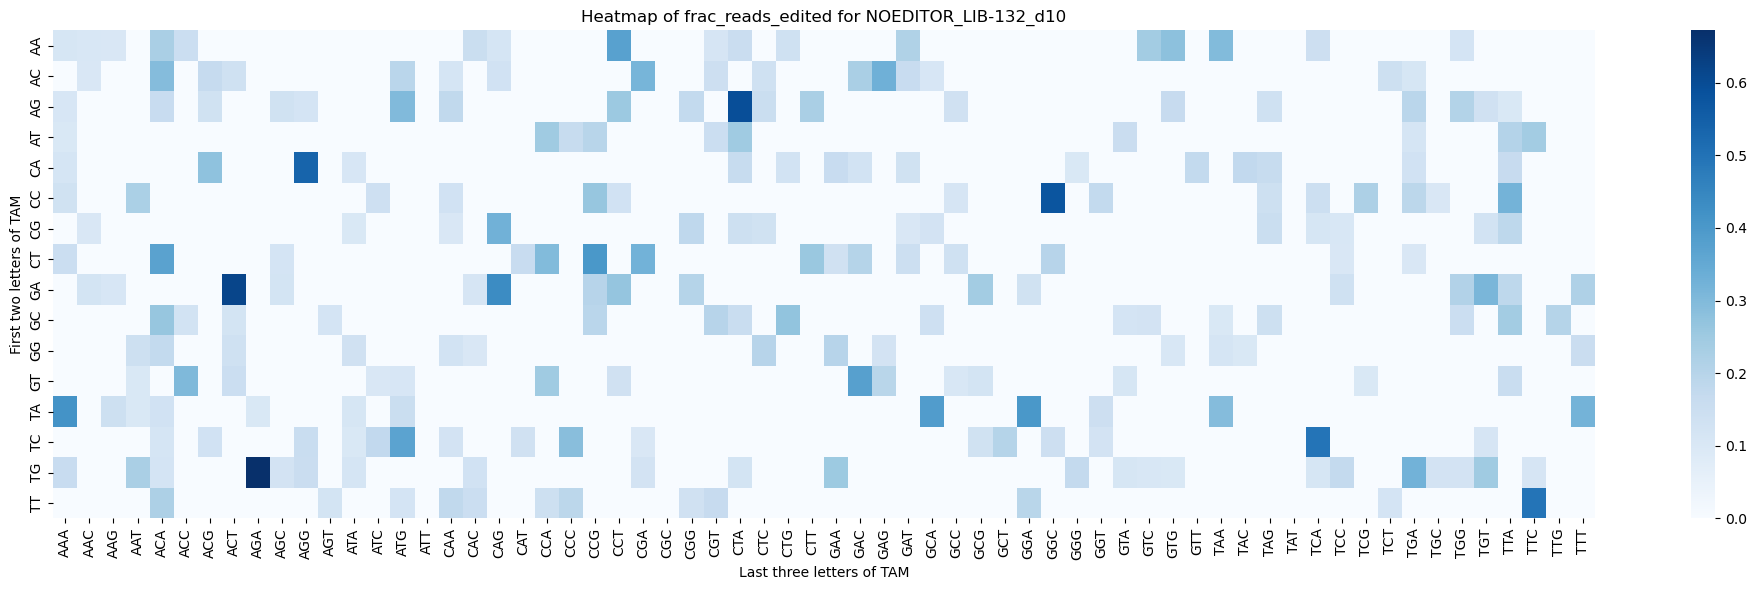

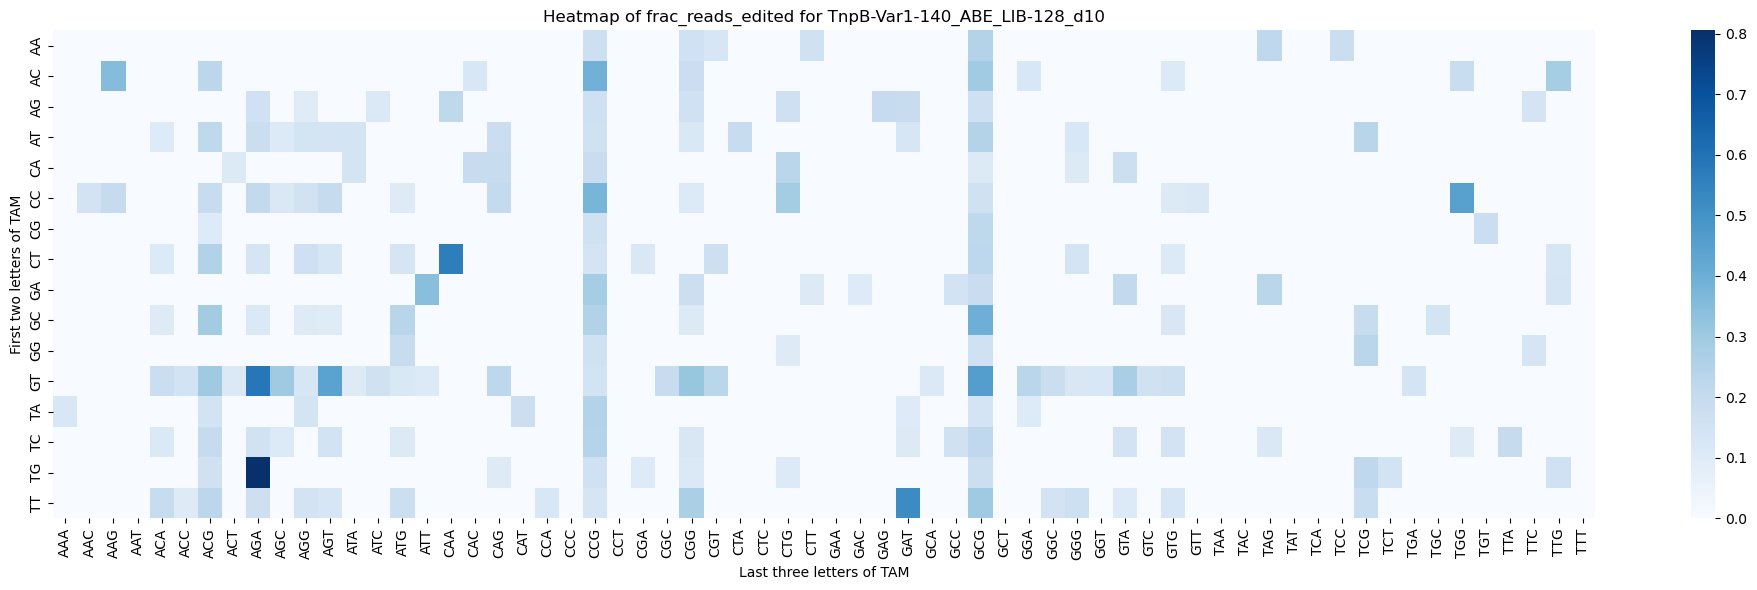

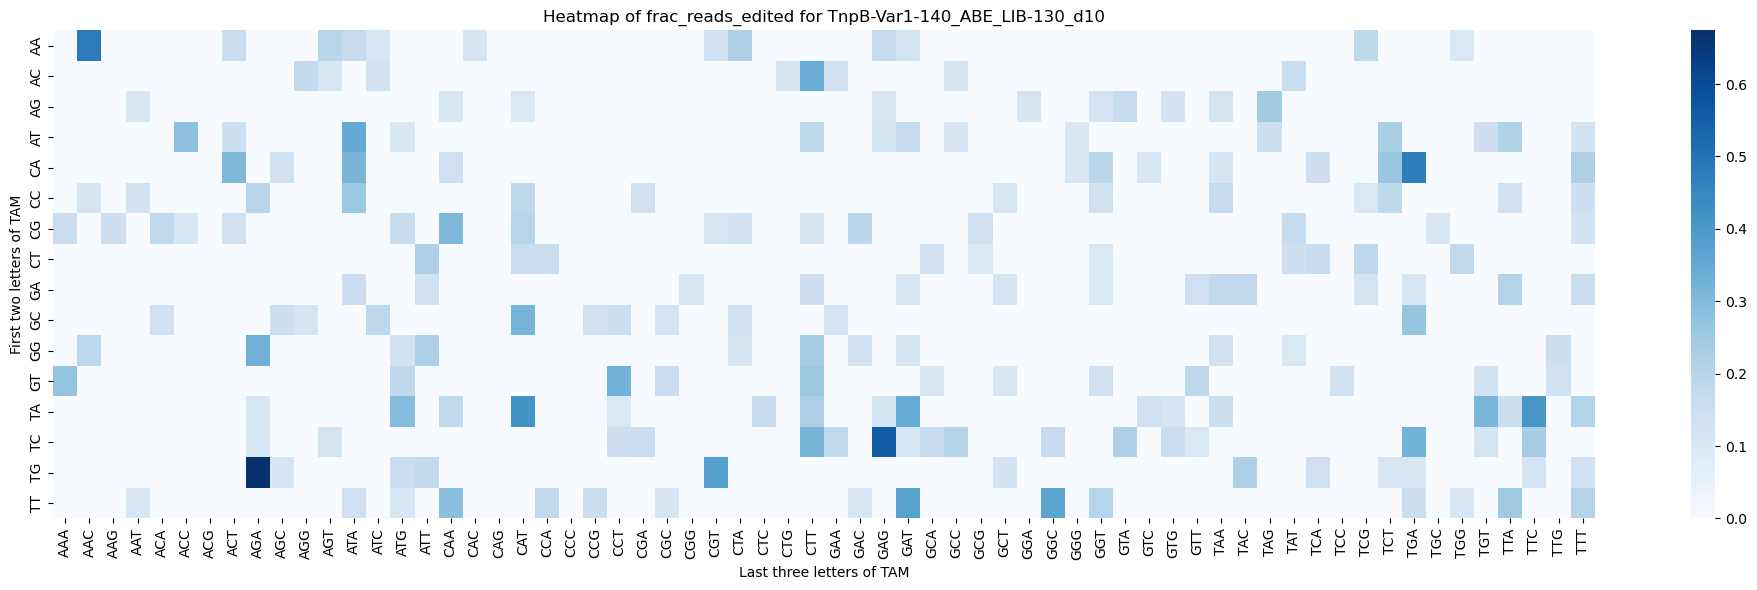

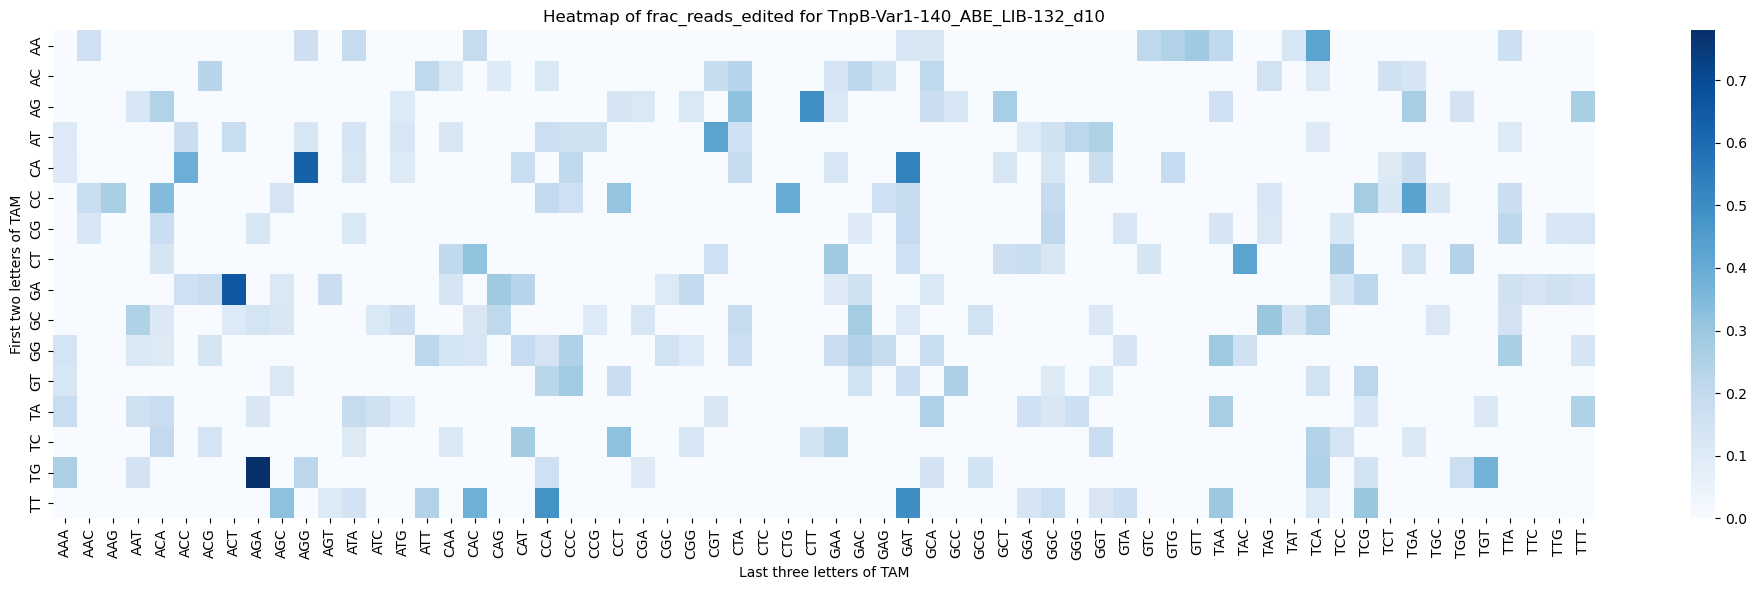

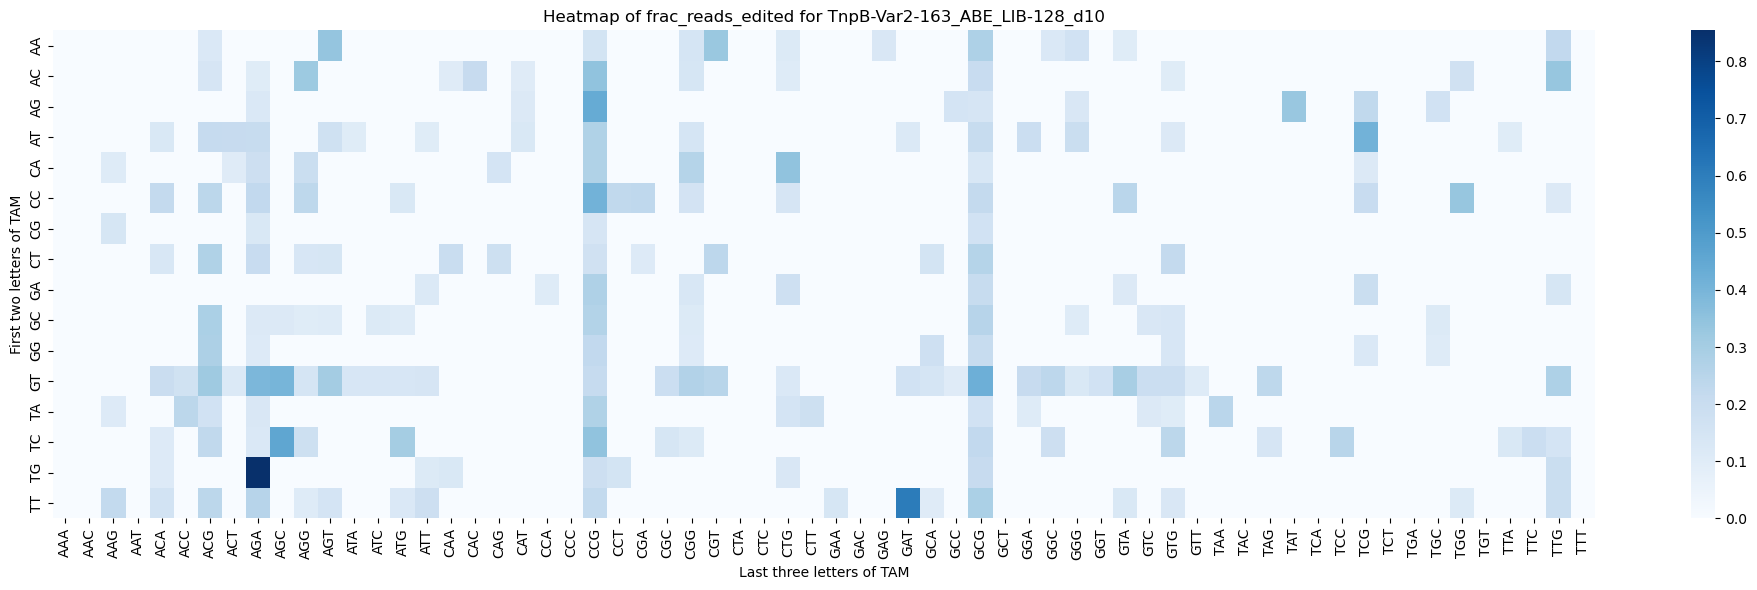

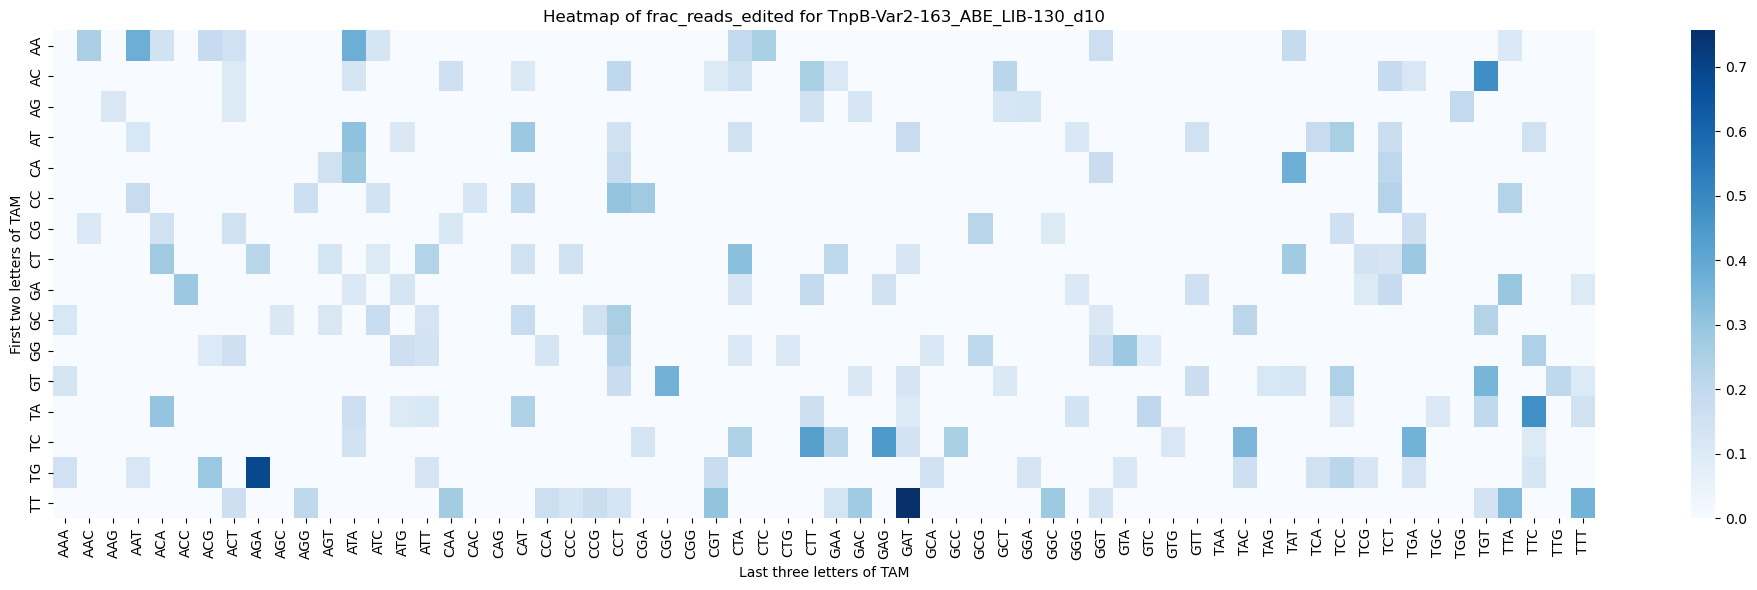

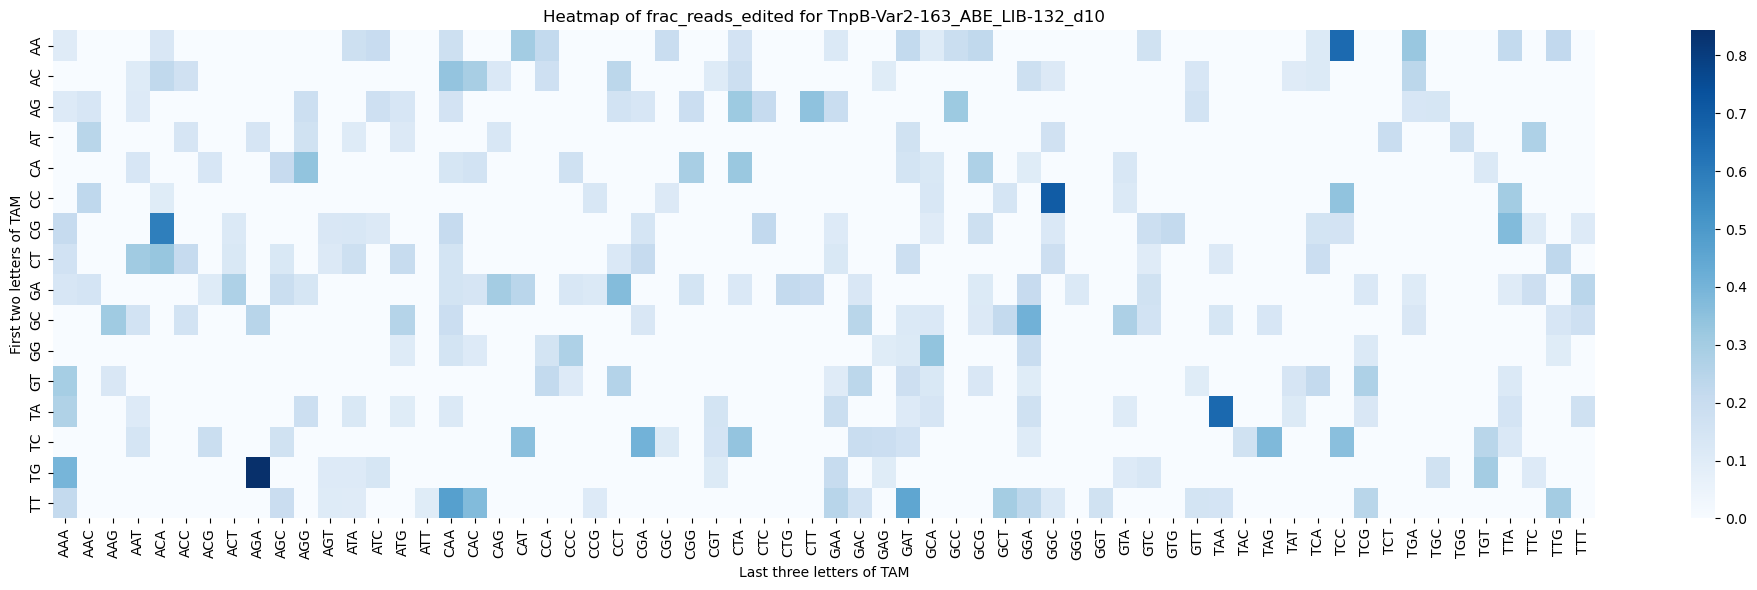

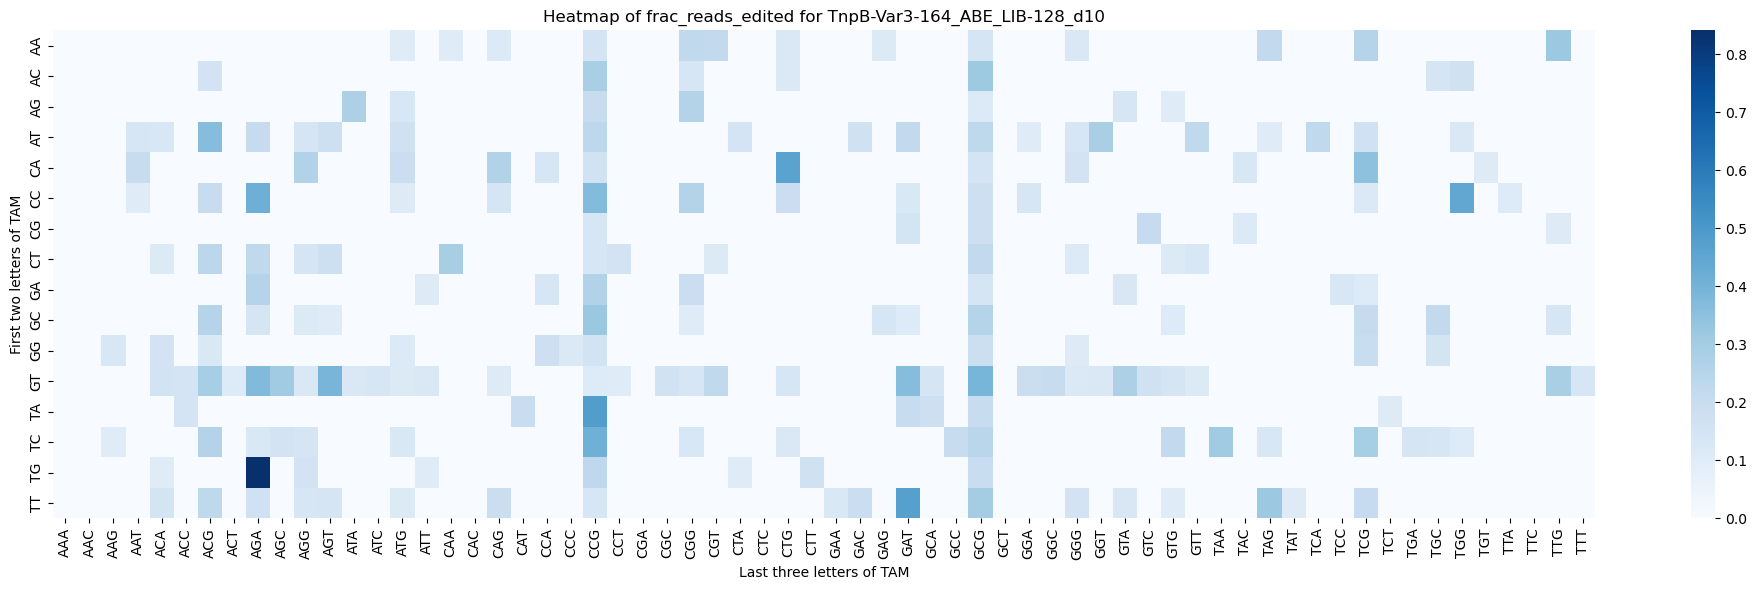

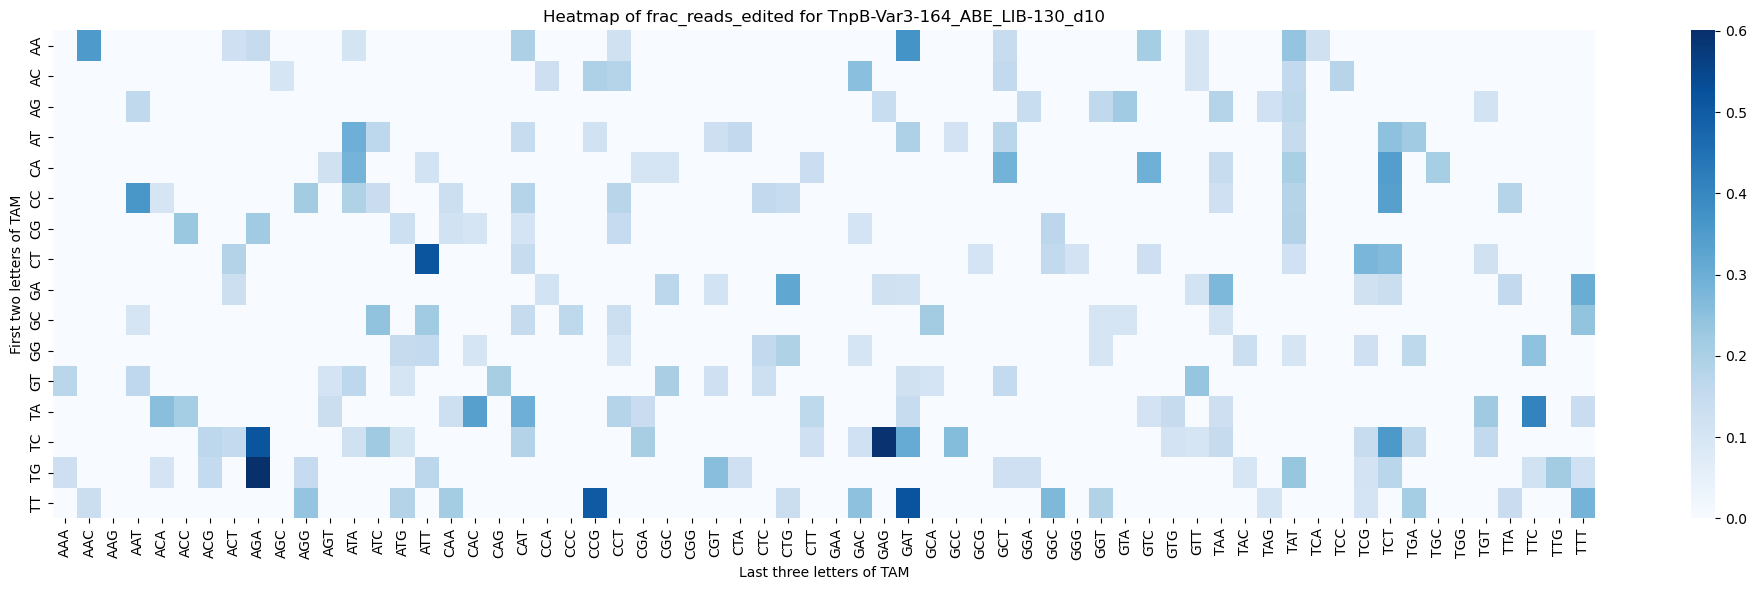

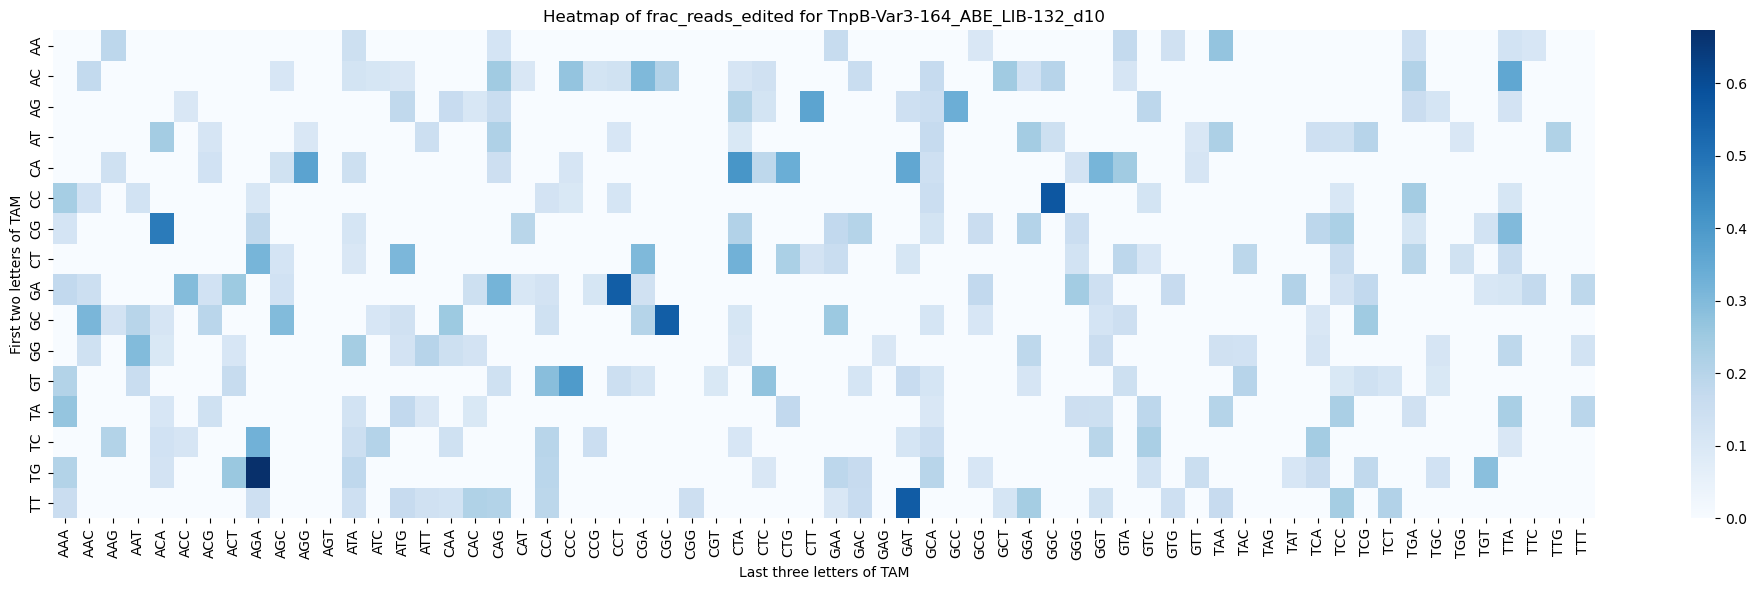

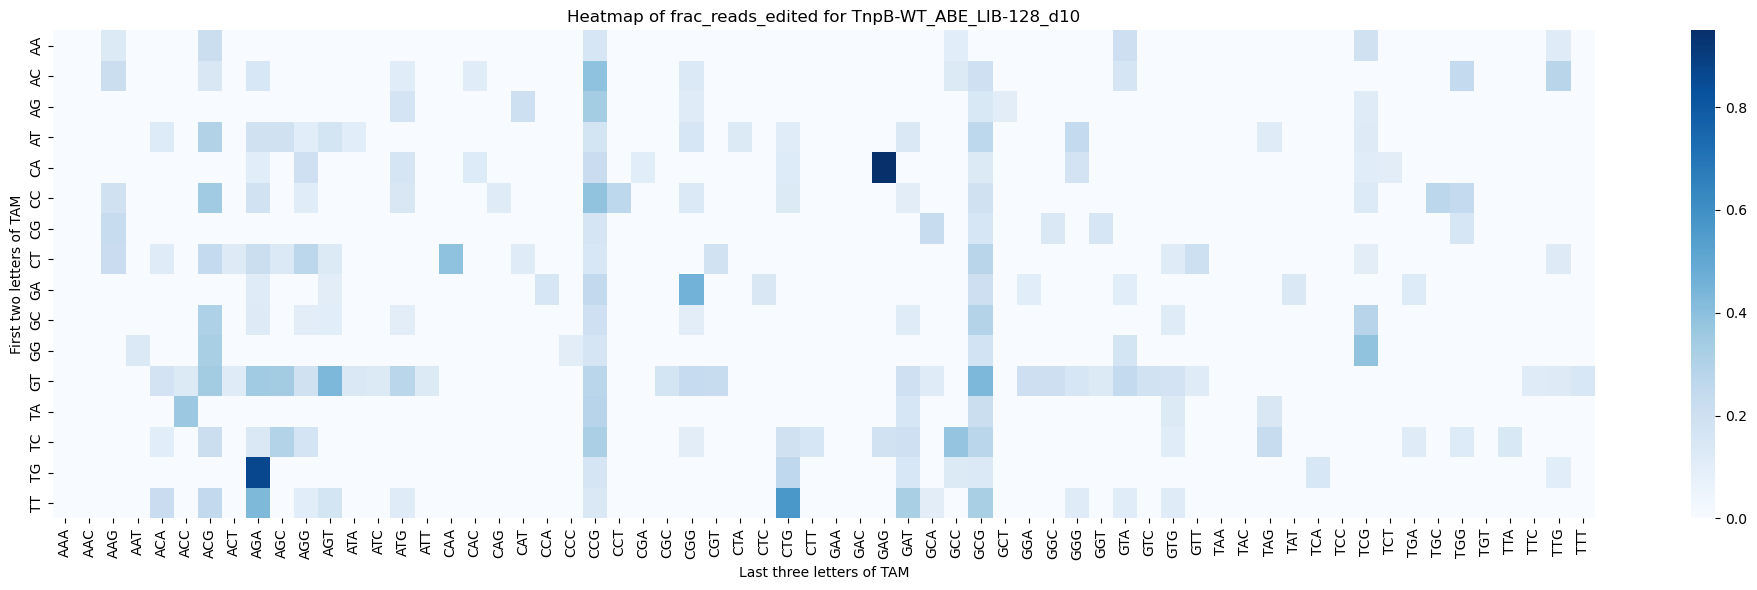

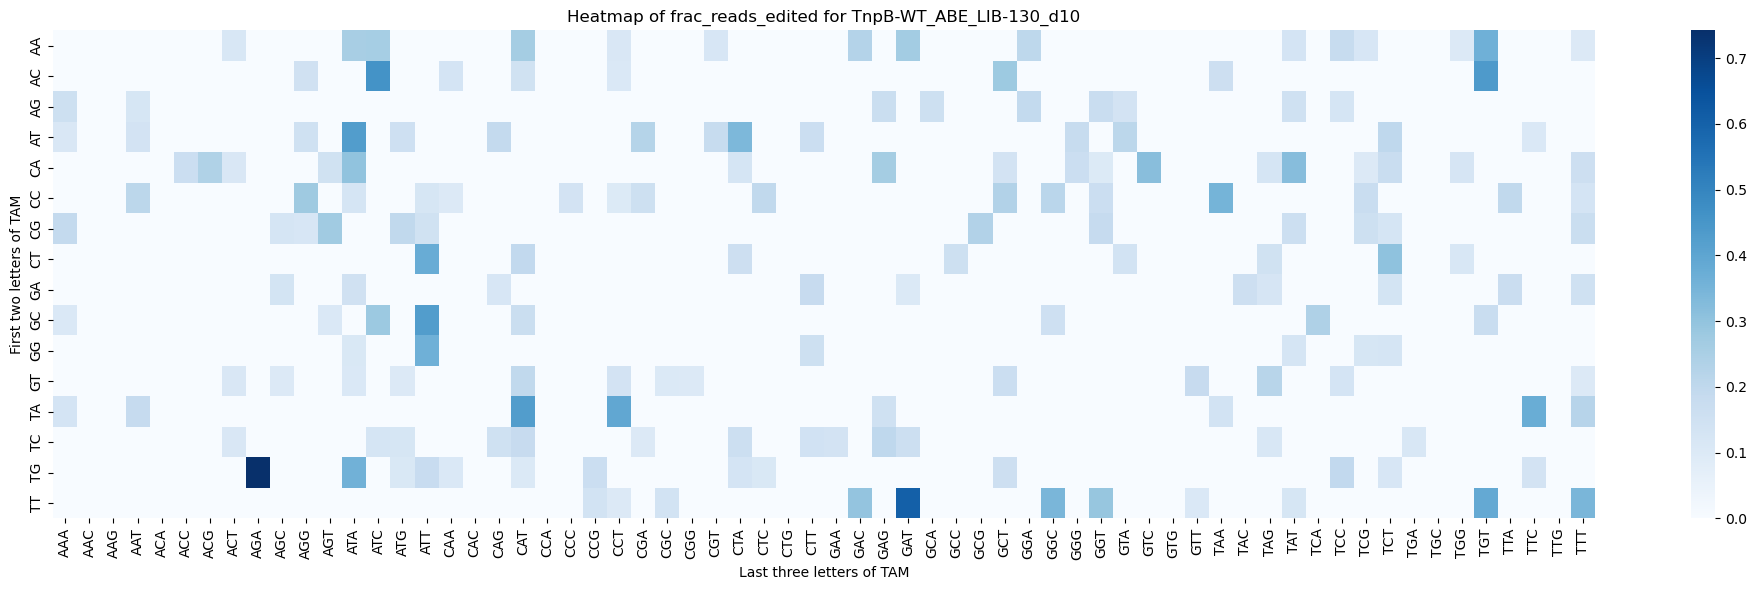

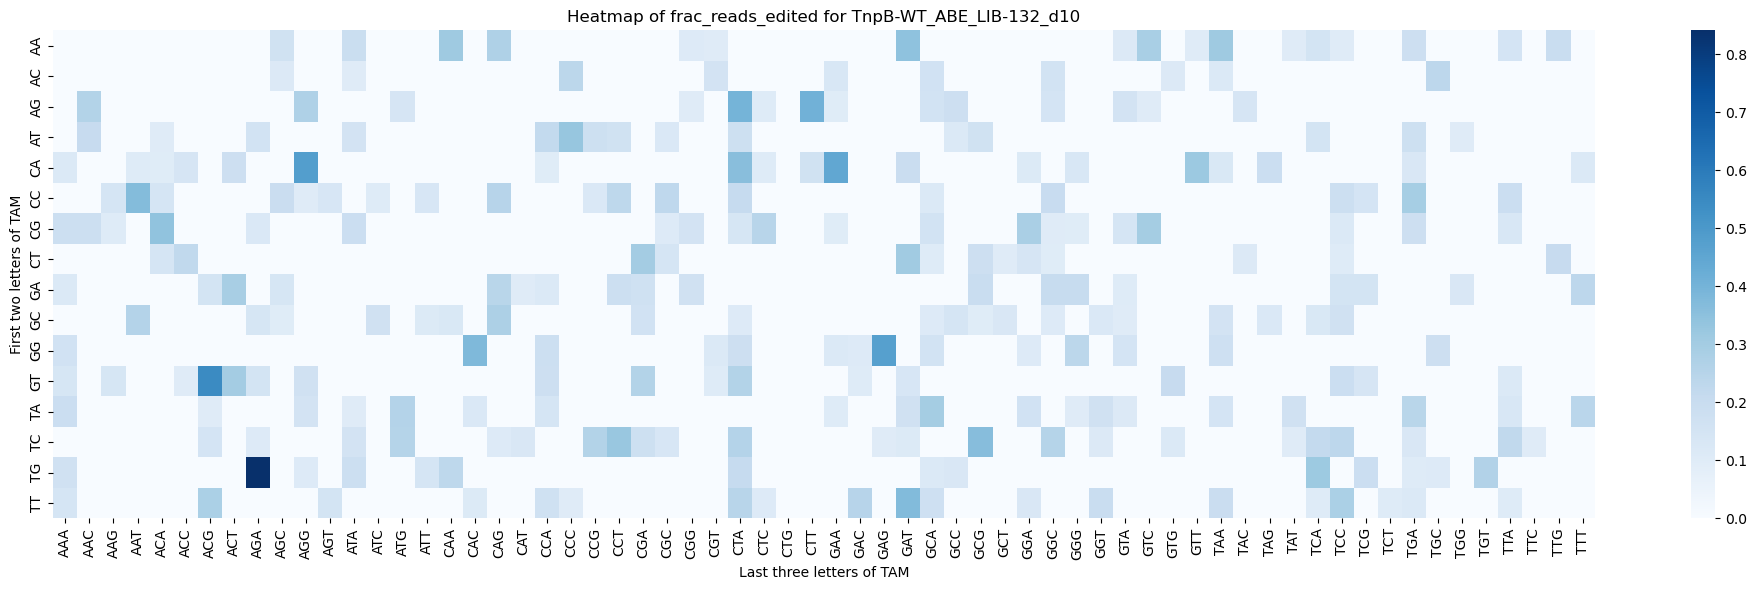

In [30]:
vis_bioreplicates=sorted(mean_fracs_not_normalized.bioreplicate.unique())
for bioreplicate in vis_bioreplicates:
    plot_heatmap_for_bioreplicate(mean_fracs_not_normalized, bioreplicate, figsize=(20,6), cmap="Blues")